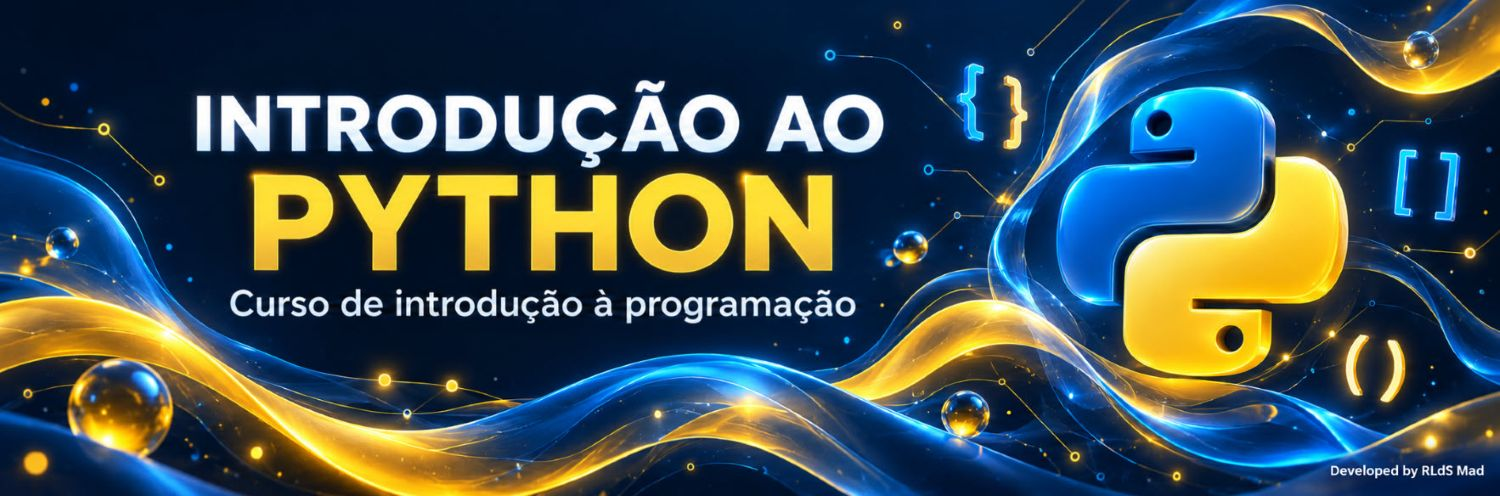

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/RLdS_N3_03_Processo_KDD.ipynb)


# Nível IA · Módulo 3 – Do dado ao conhecimento: o processo KDD
## Um caso de estudo de ponta a ponta: prever o abandono de clientes

Nos módulos anteriores aprendeste as ferramentas: o pandas para ler e limpar dados, a estatística descritiva para os resumir, o scikit-learn para treinar modelos. Neste módulo juntas tudo num **processo**. Partes de três fontes de dados «sujas» de uma loja e chegas a uma resposta que a direção pode usar: *que clientes estão em risco de abandonar a loja, porquê, e onde vale a pena agir?*

O processo que vamos seguir chama-se **KDD** (*Knowledge Discovery in Databases*, descoberta de conhecimento em bases de dados) e tem seis fases. No fim, ficas com uma **estrutura reutilizável**: um módulo `kdd.py` com as funções de cada fase e um notebook-modelo para aplicares o processo aos teus próprios dados.

> **Objetivos:** conhecer as seis fases do processo KDD e a relação com o CRISP-DM; selecionar dados de várias fontes (CSV, base de dados SQLite, JSON de uma API) e definir uma janela temporal; limpar duplicados, inconsistências, valores impossíveis e valores em falta, registando as decisões; normalizar, codificar e criar atributos; reduzir a dimensionalidade com seleção de atributos e PCA; aplicar classificação e agrupamento; avaliar e interpretar os resultados, incluindo o *lift*; reconhecer e evitar fugas de informação (*data leakage*); reutilizar o processo com o módulo `kdd.py`.

**Pré-requisitos:** pandas (capítulo 23 e módulo N2_01), visualização (capítulo 24), scikit-learn (módulos N2_03 e N2_04) e estatística descritiva (módulos N3_01 e N3_02). O módulo N2_05 (PCA e agrupamento) e o anexo A2 (do notebook ao projeto) ajudam, mas não são obrigatórios.

| Secção | Fase do KDD |
| --- | --- |
| 0. O processo KDD | visão geral e caso de estudo |
| 1. Seleção | escolher e extrair os dados relevantes |
| 2. Limpeza | duplicados, inconsistências, ruído, valores em falta |
| 3. Transformação | agregar, criar atributos, normalizar, codificar |
| 4. Redução | seleção de atributos e PCA |
| 5. Mineração | classificação e agrupamento |
| 6. Avaliação | métricas, *lift*, interpretação e utilidade |
| 7. Estrutura reutilizável | `kdd.py`, lista de verificação e notebook-modelo |


## 0. O processo KDD

Fayyad, Piatetsky-Shapiro e Smyth (1996) definiram o KDD como o processo, não trivial, de identificar nos dados **padrões válidos, novos, potencialmente úteis e compreensíveis**. Repara nos quatro adjetivos: vamos voltar a eles na avaliação (secção 6). A **mineração de dados** (*data mining*) é só uma das fases: a que aplica os algoritmos. Tudo o que vem antes decide se os algoritmos têm alguma coisa de útil para encontrar.

| Fase | Pergunta | Ferramentas neste módulo | Onde se aprofunda |
| --- | --- | --- | --- |
| **1. Seleção** | Que dados respondem à pergunta, e de que período? | `read_csv`, `sqlite3` + SQL, `json` + `json_normalize` | N2_01 §4–5, N2_02 §3 |
| **2. Limpeza** | Os dados estão corretos e completos? | `duplicated`, `str.strip/lower`, regras de domínio, IQR | N2_01 §6–8, N2_02 §5 |
| **3. Transformação** | Os dados estão na forma que o algoritmo precisa? | `groupby`, `merge`, `StandardScaler`, `OneHotEncoder` | N2_01 §9–10, N2_02 §9 |
| **4. Redução** | Precisamos de todos os atributos? | correlação, informação mútua, `SelectKBest`, `PCA` | N2_05 §10 |
| **5. Mineração** | Que padrões existem? | `LogisticRegression`, `RandomForestClassifier`, `KMeans` | N2_03, N2_04, N2_05 |
| **6. Avaliação** | Os padrões são válidos, úteis e acionáveis? | validação cruzada, matriz de confusão, ROC, *lift*, importância | N2_04 §3, §8–10 |

Na literatura, a limpeza, a transformação e a redução aparecem muitas vezes juntas, sob o nome **pré-processamento**, o que dá um modelo de cinco fases: seleção → pré-processamento → mineração → avaliação, mais a transformação separada ou incluída, conforme o autor. As tarefas são as mesmas; muda só o agrupamento.

O processo **não é linear**: é normal descobrir na avaliação que falta um atributo (voltar à seleção) ou que uma limpeza foi demasiado agressiva (voltar à limpeza). O diagrama mostra as fases e esse ciclo de retorno.


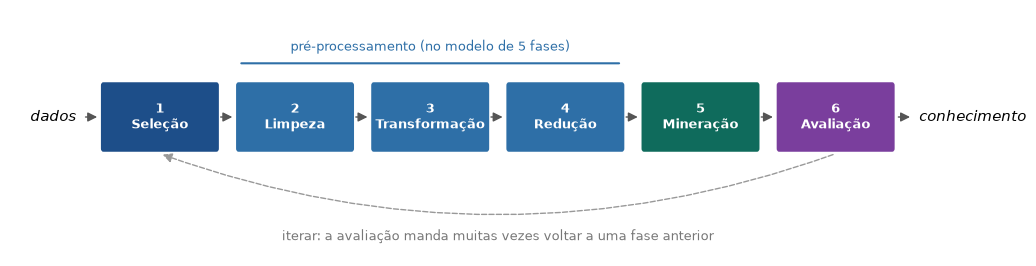

In [1]:
# Executar esta célula

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fases = ["Seleção", "Limpeza", "Transformação", "Redução", "Mineração", "Avaliação"]
cores = ["#1D4E89", "#2E6FA7", "#2E6FA7", "#2E6FA7", "#0F6B5C", "#7A3E9D"]
L, P = 2.3, 2.75                                  # largura de cada caixa e distância entre caixas
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.set_xlim(-1.9, 18.6), ax.set_ylim(-1.7, 2.2), ax.axis("off")

ax.text(-0.55, 0.5, "dados", ha="right", va="center", fontsize=11, style="italic")
ax.text(5 * P + L + 0.55, 0.5, "conhecimento", ha="left", va="center", fontsize=11, style="italic")
for i, (fase, cor) in enumerate(zip(fases, cores)):
    x = i * P
    ax.add_patch(FancyBboxPatch((x, 0), L, 1, boxstyle="round,pad=0.05", fc=cor, ec="none"))
    ax.text(x + L / 2, 0.5, f"{i + 1}\n{fase}", ha="center", va="center", color="white", fontsize=9.5, weight="bold")
    ax.add_patch(FancyArrowPatch((x - 0.42, 0.5), (x - 0.07, 0.5), arrowstyle="-|>", mutation_scale=14, color="#555"))
ax.add_patch(FancyArrowPatch((5 * P + L + 0.07, 0.5), (5 * P + L + 0.42, 0.5), arrowstyle="-|>",
                             mutation_scale=14, color="#555"))

ax.annotate("", xy=(P, 1.35), xytext=(3 * P + L, 1.35), arrowprops=dict(arrowstyle="-", color="#2E6FA7", lw=1.5))
ax.text((P + 3 * P + L) / 2, 1.55, "pré-processamento (no modelo de 5 fases)", ha="center", color="#2E6FA7", fontsize=9)
ax.add_patch(FancyArrowPatch((5 * P + L / 2, -0.08), (L / 2, -0.08), connectionstyle="arc3,rad=-0.18",
                             arrowstyle="-|>", mutation_scale=14, color="#999", ls="--"))
ax.text((5 * P + L) / 2, -1.45, "iterar: a avaliação manda muitas vezes voltar a uma fase anterior",
        ha="center", color="#777", fontsize=9)
plt.show()

### 0.1 KDD, CRISP-DM e SEMMA

Existem outros modelos do mesmo processo. O mais usado na indústria é o **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*, 2000), que acrescenta duas fases que o KDD deixa implícitas: **perceber o negócio** no início e **pôr em produção** no fim. O **SEMMA** (da SAS) é outra variante, com cinco fases.

| KDD | CRISP-DM |
| --- | --- |
| *(implícito: definir o objetivo)* | 1. Compreensão do negócio |
| 1. Seleção | 2. Compreensão dos dados |
| 2. Limpeza · 3. Transformação · 4. Redução | 3. Preparação dos dados |
| 5. Mineração | 4. Modelação |
| 6. Avaliação | 5. Avaliação |
| *(implícito: usar o conhecimento)* | 6. Implementação (*deployment*) |

Neste módulo seguimos as seis fases do KDD, mas começamos como o CRISP-DM recomenda: com a pergunta de negócio e um critério de sucesso.

### 0.2 O caso de estudo

Uma cadeia de lojas (fictícia) tem um cartão de cliente. A direção quer reduzir os cancelamentos e pergunta:

1. **Que clientes estão em risco de cancelar o cartão no 4.º trimestre de 2025?** (um problema de **classificação**)
2. **Que tipos de clientes temos?** (um problema de **agrupamento**, para orientar as campanhas)

**Critério de sucesso**, definido *antes* de olhar para os dados: a campanha de retenção só consegue contactar **20 % dos clientes**. O modelo é útil se, nesses 20 %, estiverem muito mais do que 20 % dos clientes que vão cancelar.

Os dados estão espalhados por três sistemas: a ficha de clientes (CRM), as vendas (base de dados) e o apoio ao cliente (uma API).

### 0.3 Bibliotecas


In [2]:
# Executar esta célula

import json
import sqlite3
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             roc_auc_score, silhouette_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.0.6 | scikit-learn 1.9.1


## 1. Seleção: identificar e extrair os dados relevantes

A seleção responde a três perguntas: **de onde** vêm os dados, **que parte** interessa (linhas, colunas, período) e **como** se extraem de forma reprodutível. É a fase mais subestimada: um erro aqui (o período errado, uma fonte esquecida) não se corrige com nenhum algoritmo.

### 1.1 Criar as fontes de dados (simulação)

Num projeto real, as fontes já existem. Aqui, a célula seguinte **simula** os três sistemas da loja e grava-os na pasta `dados_loja`: um CSV exportado do CRM, uma base de dados SQLite com as vendas e um ficheiro JSON com a resposta de uma API de apoio ao cliente. Os dados são gerados com uma semente fixa, por isso são sempre iguais, e têm «sujidade» realista introduzida de propósito.

> Não precisas de perceber esta célula para seguir o módulo: executa-a e continua. Se tiveres curiosidade, ela mostra como se geram dados sintéticos com uma estrutura conhecida (secção «o mundo real») e depois se «estragam» como os dados reais costumam estar.


In [3]:
# Executar esta célula

import json
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd

PASTA = Path("dados_loja")
PASTA.mkdir(exist_ok=True)
rng = np.random.default_rng(2025)
N = 1500
DATA_REF = pd.Timestamp("2025-12-31")

# --- características «verdadeiras» de cada cliente (o mundo real, que não observamos diretamente)
ids = [f"C{i:04d}" for i in range(1, N + 1)]
idade = np.clip(rng.normal(42, 13, N), 18, 85).round()
cidade = rng.choice(["Lisboa", "Porto", "Braga", "Coimbra", "Faro", "Aveiro"], N,
                    p=[0.32, 0.24, 0.12, 0.12, 0.10, 0.10])
canal = rng.choice(["loja", "online", "app"], N, p=[0.40, 0.35, 0.25])
plano = rng.choice(["Básico", "Plus", "Premium"], N, p=[0.55, 0.30, 0.15])
registo = DATA_REF - pd.to_timedelta(rng.integers(200, 1800, N), unit="D")
reclamacoes = rng.poisson(np.where(rng.random(N) < 0.2, 2.5, 0.4))
satisfacao = np.clip(np.round(4.1 - 0.45 * reclamacoes + rng.normal(0, 0.8, N)), 1, 5)

nivel_plano = pd.Series(plano).map({"Básico": 0, "Plus": 1, "Premium": 2}).to_numpy()
logit = (-1.2 + 0.55 * reclamacoes - 0.55 * (satisfacao - 3) - 0.5 * nivel_plano
         - 0.012 * (idade - 42) + 0.45 * (canal == "online") - 0.25 * (canal == "app")
         + rng.normal(0, 0.6, N))
abandonou = rng.random(N) < 1 / (1 + np.exp(-logit))

# --- fonte 1: vendas (base de dados SQLite), ano de 2025
linhas = []
for i in range(N):
    taxa = 9 + 6 * nivel_plano[i] + 3 * (canal[i] == "app")
    if abandonou[i]:                                         # cancela no 4.º trimestre (dias 273 a 364)
        fim = int(rng.integers(273, 365))
        antes = rng.poisson(taxa * 0.75 * 180 / 365)             # 1.º semestre: compra um pouco menos
        depois = rng.poisson(taxa * 0.55 * (fim - 180) / 365)    # a seguir: compra ainda menos
        dias = np.sort(np.r_[rng.integers(0, 180, antes), rng.integers(180, fim, depois)])
    else:
        dias = np.sort(rng.integers(0, 365, rng.poisson(taxa)))
    for d in dias:
        valor = round(float(rng.lognormal(3.3 + 0.25 * nivel_plano[i], 0.6)), 2)
        cat = rng.choice(["mercearia", "casa", "eletrónica", "moda", "desporto"],
                         p=[0.40, 0.20, 0.12, 0.18, 0.10])
        linhas.append((ids[i], (pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(d))).date().isoformat(), valor, cat))
vendas = pd.DataFrame(linhas, columns=["id_cliente", "data", "valor", "categoria"])
dev = rng.random(len(vendas)) < 0.03                                   # devoluções: valor negativo
vendas.loc[dev, "valor"] = -vendas.loc[dev, "valor"]
erro = rng.choice(len(vendas), 4, replace=False)                       # erros de registo
vendas.loc[erro, "valor"] = [99999.0, 45000.0, 99999.0, 0.0]
antigas = pd.DataFrame({"id_cliente": rng.choice(ids, 400), "data": "2024-11-15",
                        "valor": 30.0, "categoria": "mercearia"})      # vendas de 2024 (fora do período)
vendas = pd.concat([antigas, vendas], ignore_index=True)
vendas.insert(0, "id_venda", range(1, len(vendas) + 1))
with sqlite3.connect(PASTA / "loja.db") as con:
    vendas.to_sql("vendas", con, if_exists="replace", index=False)
con.close()

# --- fonte 2: ficha de clientes (CSV exportado do CRM), com «sujidade»
clientes = pd.DataFrame({
    "id_cliente": ids,
    "data_registo": registo.strftime("%Y-%m-%d"),
    "idade": idade,
    "cidade": cidade,
    "canal_preferido": canal,
    "plano": plano,
    "pais": "Portugal",
    "estado": np.where(abandonou, "cancelado", "ativo"),
})
sujo = clientes.copy()
k = rng.choice(N, 140, replace=False)
sujo.loc[k[:50], "cidade"] = sujo.loc[k[:50], "cidade"].str.upper()
sujo.loc[k[50:90], "cidade"] = " " + sujo.loc[k[50:90], "cidade"].str.lower() + " "
sujo.loc[k[90:100], "cidade"] = np.nan
sujo.loc[k[100:110], "plano"] = "basico"
sujo.loc[k[110:130], "idade"] = np.nan
sujo.loc[k[130:134], "idade"] = [230, 0, 410, -1]
sujo.loc[k[134:140], "estado"] = ["Cancelado", "ATIVO", "Ativo ", "cancelado ", "Ativo", "CANCELADO"]
sujo = pd.concat([sujo, sujo.sample(30, random_state=1)], ignore_index=True)   # duplicados
sujo = sujo.sample(frac=1, random_state=2).reset_index(drop=True)
sujo.to_csv(PASTA / "clientes.csv", index=False, encoding="utf-8")

# --- fonte 3: resposta de uma API de apoio ao cliente (JSON aninhado), só para quem contactou
registos = []
for i in range(N):
    if reclamacoes[i] == 0 and rng.random() < 0.35:
        continue                                                      # nunca contactou o apoio
    registos.append({
        "cliente": {"id": ids[i]},
        "contactos": {"reclamacoes": int(reclamacoes[i]), "pedidos_informacao": int(rng.poisson(1.2))},
        "satisfacao": None if rng.random() < 0.08 else int(satisfacao[i]),
    })
resposta = {"periodo": {"inicio": "2025-01-01", "fim": "2025-09-30"}, "pagina": 1,
            "total": len(registos), "resultados": registos}
(PASTA / "apoio_api.json").write_text(json.dumps(resposta, ensure_ascii=False, indent=1), encoding="utf-8")

print(f"Clientes: {len(sujo)} linhas | vendas: {len(vendas)} | registos de apoio: {len(registos)}")

Clientes: 1530 linhas | vendas: 18472 | registos de apoio: 1183


### 1.2 Conhecer as fontes

Antes de extrair, olha para cada fonte: que colunas tem, que granularidade (uma linha por quê?), que período cobre.

| Fonte | Sistema | Formato | Uma linha é… |
| --- | --- | --- | --- |
| `clientes.csv` | CRM (ficha de cliente) | CSV | um cliente (em princípio…) |
| `loja.db`, tabela `vendas` | ERP (faturação) | base de dados SQLite | uma venda ou devolução |
| `apoio_api.json` | apoio ao cliente | JSON aninhado | um cliente que contactou o apoio |


In [4]:
# Executar esta célula

PASTA = Path("dados_loja")

clientes_bruto = pd.read_csv(PASTA / "clientes.csv")
print("CRM:", clientes_bruto.shape)
display(clientes_bruto.head())

with sqlite3.connect(PASTA / "loja.db") as con:
    print(pd.read_sql_query("PRAGMA table_info(vendas)", con)[["name", "type"]].to_string(index=False))
    display(pd.read_sql_query("""SELECT substr(data, 1, 7) AS mes, COUNT(*) AS vendas
                                 FROM vendas GROUP BY mes ORDER BY mes""", con).T)
con.close()

resposta_api = json.loads((PASTA / "apoio_api.json").read_text(encoding="utf-8"))
print("API: chaves", list(resposta_api), "| período", resposta_api["periodo"], "| registos", resposta_api["total"])
print(json.dumps(resposta_api["resultados"][0], ensure_ascii=False))

CRM: (1530, 8)


,id_cliente,data_registo,idade,cidade,canal_preferido,plano,pais,estado
0,C1332,2024-09-14,23.0,Lisboa,app,Premium,Portugal,ativo
1,C1313,2025-03-05,29.0,Braga,online,Premium,Portugal,ativo
2,C0730,2024-01-11,39.0,Lisboa,loja,Premium,Portugal,ativo
3,C0324,2024-09-09,39.0,Faro,online,Plus,Portugal,ativo
4,C0682,2024-10-07,32.0,Coimbra,online,Plus,Portugal,ativo


      name    type
  id_venda INTEGER
id_cliente    TEXT
      data    TEXT
     valor    REAL
 categoria    TEXT


,0,1,2,3,4,5,6,7,8,9,10,11,12
mes,2024-11,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
vendas,400,1678,1481,1576,1579,1642,1565,1483,1492,1428,1524,1304,1320


API: chaves ['periodo', 'pagina', 'total', 'resultados'] | período {'inicio': '2025-01-01', 'fim': '2025-09-30'} | registos 1183
{"cliente": {"id": "C0001"}, "contactos": {"reclamacoes": 0, "pedidos_informacao": 1}, "satisfacao": 3}


Três observações que vão orientar as decisões seguintes:

- a tabela de vendas tem um mês de **2024** (novembro) que não interessa para a pergunta;
- a API só cobre **janeiro a setembro de 2025** e só tem os clientes que contactaram o apoio;
- no CRM, a coluna `estado` (`ativo`/`cancelado`) é a situação a **31 de dezembro de 2025**: é o que queremos prever.

### 1.3 Definir a janela temporal: a decisão mais importante da seleção

Queremos prever o cancelamento **no 4.º trimestre**. Se usarmos as vendas de outubro a dezembro como atributos, estamos a usar informação que só existe *depois* (ou por causa) do cancelamento: quem cancela em novembro deixa de comprar em novembro. O modelo pareceria excelente no notebook e seria inútil na vida real, porque no dia em que o usarmos (30 de setembro) esse futuro ainda não aconteceu.

A este erro chama-se **fuga de informação** (*data leakage*). A regra para o evitar é separar o tempo em duas janelas:

```text
          janela de observação (atributos)          │  janela de previsão (alvo)
  2025-01-01 ─────────────────────────── 2025-09-30 │ 2025-10-01 ─────── 2025-12-31
  vendas, contactos com o apoio, ficha do cliente   │  cancelou o cartão?
```

Na secção 7.3 vais ver o que acontece aos resultados quando esta regra não é respeitada.

### 1.4 Extrair os dados

Com as decisões tomadas, extraímos só o que interessa. Da base de dados, pedimos as vendas da janela de observação com uma **consulta parametrizada** (os valores vão em `params`, nunca colados no texto do SQL). Do JSON, achatamos a estrutura aninhada com `pd.json_normalize`.


In [5]:
# Executar esta célula

INICIO, FIM = "2025-01-01", "2025-09-30"          # janela de observação
DATA_CORTE = pd.Timestamp(FIM)

consulta = """
    SELECT id_cliente, data, valor, categoria
    FROM vendas
    WHERE data BETWEEN :inicio AND :fim
"""
with sqlite3.connect(PASTA / "loja.db") as con:
    vendas_bruto = pd.read_sql_query(consulta, con, params={"inicio": INICIO, "fim": FIM})
con.close()
print("Vendas na janela:", vendas_bruto.shape)

apoio = pd.json_normalize(resposta_api["resultados"]).rename(columns={
    "cliente.id": "id_cliente",
    "contactos.reclamacoes": "reclamacoes",
    "contactos.pedidos_informacao": "pedidos_info",
})
print("Apoio ao cliente:", apoio.shape)
apoio.head()

Vendas na janela: (13924, 4)
Apoio ao cliente: (1183, 4)


,satisfacao,id_cliente,reclamacoes,pedidos_info
0,3.0,C0001,0,1
1,4.0,C0002,1,0
2,2.0,C0004,0,0
3,3.0,C0005,4,2
4,NaN,C0006,0,0


**Experimenta:** escreve uma consulta SQL que devolva, para a janela de observação, o número de vendas e o valor total por `categoria`, ordenado do maior para o menor valor. Dica: `GROUP BY categoria ORDER BY total DESC`.


In [6]:
# Executar esta célula

# Utiliza esta célula para as tuas experiências

## 2. Limpeza: tratar ruído, inconsistências, duplicados e valores em falta

Limpar não é «apagar o que parece mal»: é **diagnosticar**, **decidir** e **registar** cada decisão, para que outra pessoa (ou tu, daqui a um mês) perceba porque é que os números finais são os que são. Vamos guardar as decisões numa lista, `registo`.

### 2.1 Diagnóstico

A função `diagnosticar` resume cada coluna: tipo, valores em falta, número de valores distintos e alguns exemplos. É o primeiro passo com qualquer tabela nova.


In [7]:
# Executar esta célula

def diagnosticar(df: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por coluna: tipo, valores em falta, valores distintos e exemplos."""
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "em_falta": df.isna().sum(),
        "pct_falta": (df.isna().mean() * 100).round(1),
        "distintos": df.nunique(dropna=True),
        "exemplos": [df[c].dropna().unique()[:4].tolist() for c in df.columns],
    })
    print(f"{len(df)} linhas × {df.shape[1]} colunas | linhas duplicadas: {df.duplicated().sum()}")
    return resumo


registo = []          # registo das decisões de limpeza
diagnosticar(clientes_bruto)

1530 linhas × 8 colunas | linhas duplicadas: 30


,tipo,em_falta,pct_falta,distintos,exemplos
id_cliente,str,0,0.0,1500,"[C1332, C1313, C0730, C0324]"
data_registo,str,0,0.0,972,"[2024-09-14, 2025-03-05, 2024-01-11, 2024-09-09]"
idade,float64,20,1.3,66,"[23.0, 29.0, 39.0, 32.0]"
cidade,str,10,0.7,18,"[Lisboa, Braga, Faro, Coimbra]"
canal_preferido,str,0,0.0,3,"[app, online, loja]"
plano,str,0,0.0,4,"[Premium, Plus, Básico, basico]"
pais,str,0,0.0,1,[Portugal]
estado,str,0,0.0,8,"[ativo, cancelado, Ativo , cancelado ]"


O diagnóstico já mostra os problemas: **30 linhas duplicadas**; `cidade`, `plano` e `estado` com mais valores distintos do que devia haver (maiúsculas, espaços, acentos); `idade` com valores em falta; `pais` com um único valor; `data_registo` lida como texto.

### 2.2 Duplicados

Primeiro as linhas totalmente repetidas; depois, por precaução, a **chave** (`id_cliente`): dois registos diferentes para o mesmo cliente exigiriam uma decisão (qual é o mais recente?).


In [8]:
# Executar esta célula

def remover_duplicados(df: pd.DataFrame, chave: str | list[str] | None = None) -> pd.DataFrame:
    """Remove linhas repetidas (por todas as colunas ou pela chave) e diz quantas saíram."""
    antes = len(df)
    limpo = df.drop_duplicates(subset=chave, keep="first").reset_index(drop=True)
    print(f"Duplicados removidos: {antes - len(limpo)} (ficam {len(limpo)} linhas)")
    return limpo


clientes = remover_duplicados(clientes_bruto)
clientes = remover_duplicados(clientes, chave="id_cliente")
registo.append("CRM: removidas 30 linhas duplicadas; id_cliente passou a ser único.")

Duplicados removidos: 30 (ficam 1500 linhas)
Duplicados removidos: 0 (ficam 1500 linhas)


### 2.3 Inconsistências de texto

`"Lisboa"`, `"LISBOA"` e `" lisboa "` são o mesmo valor para nós, mas três valores diferentes para o computador. A solução é **normalizar** (tirar espaços, minúsculas, tirar acentos) e depois **mapear** para a forma oficial.


In [9]:
# Executar esta célula

import unicodedata


def normalizar_texto(serie: pd.Series, acentos: bool = True) -> pd.Series:
    """Tira espaços nas pontas, põe em minúsculas e (opcionalmente) mantém ou remove acentos."""
    # map(str) em vez de astype("string"): os valores em falta continuam NaN (e não pd.NA),
    # que é o que o scikit-learn espera
    s = serie.map(lambda t: t if pd.isna(t) else str(t)).str.strip().str.lower()
    if not acentos:
        s = s.map(lambda t: t if pd.isna(t) else
                  "".join(ch for ch in unicodedata.normalize("NFKD", t) if not unicodedata.combining(ch)))
    return s


def uniformizar_categorias(serie: pd.Series, mapa: dict[str, str] | None = None) -> pd.Series:
    """Normaliza o texto e aplica um dicionário de correspondências (forma normalizada → valor final)."""
    s = normalizar_texto(serie, acentos=False)
    if mapa:
        s = s.replace(mapa)
    return s


print("Antes:", sorted(clientes["cidade"].dropna().unique()))
clientes["cidade"] = normalizar_texto(clientes["cidade"]).str.title()
clientes["plano"] = uniformizar_categorias(clientes["plano"],
                                           {"basico": "Básico", "plus": "Plus", "premium": "Premium"})
clientes["estado"] = uniformizar_categorias(clientes["estado"])
print("Depois:", sorted(clientes["cidade"].dropna().unique()))
print(clientes["plano"].value_counts().to_dict(), clientes["estado"].value_counts().to_dict())
registo.append("CRM: cidade, plano e estado normalizados (espaços, maiúsculas e acentos).")

Antes: [' aveiro ', ' braga ', ' coimbra ', ' faro ', ' lisboa ', ' porto ', 'AVEIRO', 'Aveiro', 'BRAGA', 'Braga', 'COIMBRA', 'Coimbra', 'FARO', 'Faro', 'LISBOA', 'Lisboa', 'PORTO', 'Porto']
Depois: ['Aveiro', 'Braga', 'Coimbra', 'Faro', 'Lisboa', 'Porto']
{'Básico': 800, 'Plus': 446, 'Premium': 254} {'ativo': 1116, 'cancelado': 384}


### 2.4 Valores impossíveis

Algumas idades são impossíveis (230, 410, 0, −1): são erros de escrita. Não sabemos o valor certo, por isso o mais honesto é **transformá-los em valores em falta**, que vão ser tratados mais à frente, em vez de os apagar com o resto da linha ou de inventar um valor. A regra de domínio (idades entre 16 e 100) é uma decisão de negócio e fica registada.


In [10]:
# Executar esta célula

def invalidar_fora_do_intervalo(df: pd.DataFrame, regras: dict[str, tuple[float, float]]) -> pd.DataFrame:
    """Substitui por NaN os valores fora de [mínimo, máximo] de cada coluna. Não altera o original."""
    df = df.copy()
    for coluna, (minimo, maximo) in regras.items():
        fora = ~df[coluna].between(minimo, maximo) & df[coluna].notna()
        print(f"{coluna}: {fora.sum()} valores fora de [{minimo}, {maximo}] → NaN")
        df.loc[fora, coluna] = np.nan
    return df


clientes = invalidar_fora_do_intervalo(clientes, {"idade": (16, 100)})
clientes["data_registo"] = pd.to_datetime(clientes["data_registo"])
registo.append("CRM: idades fora de [16, 100] passaram a valor em falta; data_registo convertida em data.")

idade: 4 valores fora de [16, 100] → NaN


### 2.5 Ruído e valores extremos nas vendas

Nas vendas, o problema é outro: **ruído** e **valores extremos**. A regra de Tukey (IQR) marca como extremo tudo o que está fora de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Vejamos o que marca:


In [11]:
# Executar esta célula

def outliers_iqr(serie: pd.Series, k: float = 1.5) -> pd.Series:
    """Máscara booleana dos valores fora de [Q1 − k·IQR, Q3 + k·IQR] (regra de Tukey)."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - k * iqr) | (serie > q3 + k * iqr)


print(vendas_bruto["valor"].describe().round(2).to_dict())
extremos = outliers_iqr(vendas_bruto["valor"])
print(f"\nA regra IQR marca {extremos.sum()} vendas ({extremos.mean():.1%}), por exemplo:")
print(vendas_bruto.loc[extremos, "valor"].sort_values().iloc[[0, 1, len(vendas_bruto.loc[extremos]) // 2, -2, -1]].to_list())

{'count': 13924.0, 'mean': 56.06, 'std': 1257.48, 'min': -194.69, '25%': 21.01, '50%': 32.66, '75%': 50.62, 'max': 99999.0}

A regra IQR marca 1010 vendas (7.3%), por exemplo:
[-194.69, -177.16, 102.95, 99999.0, 99999.0]


A regra IQR marca centenas de vendas, mas a maioria são **compras grandes legítimas** (a distribuição dos valores é assimétrica, como quase sempre com dinheiro) e **devoluções** (valores negativos), que são informação, não erro. Apagá-las seria perder dados verdadeiros. A regra estatística serve para **encontrar candidatos**; a decisão faz-se com **conhecimento do negócio**:

| Caso | Decisão |
| --- | --- |
| valor = 0 | erro de registo: remover |
| \|valor\| > 5000 € (99 999, 45 000) | erro de registo: remover |
| valor < 0 | devolução: manter, e contar à parte |
| compras grandes, mas plausíveis | manter |


Vendas removidas por erro de registo: [0.0, 45000.0, 99999.0, 99999.0]


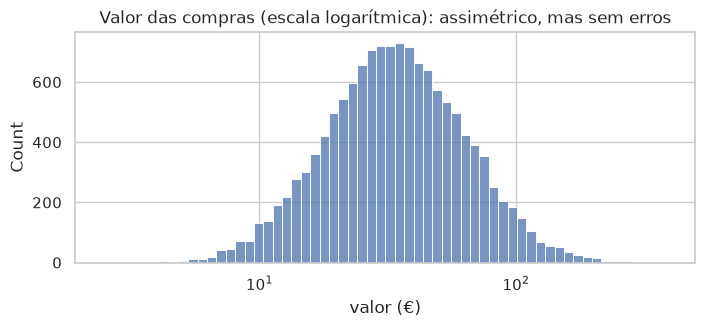

In [12]:
# Executar esta célula

erro_registo = (vendas_bruto["valor"] == 0) | (vendas_bruto["valor"].abs() > 5000)
print("Vendas removidas por erro de registo:", vendas_bruto.loc[erro_registo, "valor"].to_list())
vendas = vendas_bruto.loc[~erro_registo].copy()
vendas["data"] = pd.to_datetime(vendas["data"])

fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(vendas.loc[vendas["valor"] > 0, "valor"], bins=60, log_scale=True, ax=ax)
ax.set(title="Valor das compras (escala logarítmica): assimétrico, mas sem erros", xlabel="valor (€)")
plt.show()
registo.append(f"Vendas: removidas {erro_registo.sum()} com valor 0 ou |valor| > 5000 €; devoluções mantidas.")

### 2.6 Valores em falta: uma decisão por causa

Não há uma solução única para os valores em falta. A pergunta certa é **porque é que falta**:

| Coluna | Porque falta | Decisão |
| --- | --- | --- |
| `reclamacoes`, `pedidos_info` | o cliente nunca contactou o apoio (não está na API) | **falta estrutural**: preencher com 0 |
| `n_compras`, `gasto_total` | o cliente não comprou na janela | falta estrutural: preencher com 0 |
| `satisfacao` | o cliente contactou mas não respondeu ao inquérito, ou nunca contactou | **imputar** a mediana e acrescentar um **indicador** «estava em falta» (não responder pode ser um sinal) |
| `idade` | não preenchida ou inválida (2.4) | imputar a mediana |
| `cidade` | não preenchida | imputar a categoria mais frequente |

As faltas estruturais preenchem-se já (secção 3.2), porque o 0 é o valor **verdadeiro**. As imputações estatísticas (mediana, moda) **não se fazem agora**: a mediana tem de ser calculada só com os dados de treino, por isso fica dentro do *pipeline* do scikit-learn (secção 3.6). Calculá-la com todos os dados é outra forma, mais subtil, de fuga de informação.

O registo das decisões de limpeza fica assim:


In [13]:
# Executar esta célula

registo.append("Faltas estruturais (sem compras, sem contactos) → 0; satisfação, idade e cidade → imputação no pipeline.")
for i, decisao in enumerate(registo, 1):
    print(f"{i}. {decisao}")

1. CRM: removidas 30 linhas duplicadas; id_cliente passou a ser único.
2. CRM: cidade, plano e estado normalizados (espaços, maiúsculas e acentos).
3. CRM: idades fora de [16, 100] passaram a valor em falta; data_registo convertida em data.
4. Vendas: removidas 4 com valor 0 ou |valor| > 5000 €; devoluções mantidas.
5. Faltas estruturais (sem compras, sem contactos) → 0; satisfação, idade e cidade → imputação no pipeline.


## 3. Transformação: pôr os dados na forma que o algoritmo precisa

Os algoritmos de aprendizagem automática esperam **uma tabela com uma linha por exemplo** (aqui, por cliente) e **só números**. A transformação faz essa ponte: agrega, junta, cria atributos, normaliza escalas e codifica categorias.

### 3.1 Agregar as vendas por cliente

As vendas têm uma linha por compra; precisamos de uma linha por cliente. Os atributos clássicos para clientes são os **RFM**: **R**ecência (dias desde a última compra), **F**requência (número de compras) e valor **M**onetário (gasto total). Juntamos ainda o número de categorias diferentes e de devoluções.


In [14]:
# Executar esta célula

compras = vendas[vendas["valor"] > 0]
por_cliente = compras.groupby("id_cliente").agg(
    n_compras=("valor", "size"),
    gasto_total=("valor", "sum"),
    ultima_compra=("data", "max"),
    n_categorias=("categoria", "nunique"),
)
por_cliente["recencia_dias"] = (DATA_CORTE - por_cliente.pop("ultima_compra")).dt.days
por_cliente["n_devolucoes"] = vendas[vendas["valor"] < 0].groupby("id_cliente").size()
por_cliente.head()

,n_compras,gasto_total,n_categorias,recencia_dias,n_devolucoes
id_cliente,,,,,
C0001,16,794.39,5,3,1.0
C0002,7,319.95,4,47,1.0
C0003,3,90.77,2,13,NaN
C0004,4,148.63,3,33,NaN
C0005,6,430.72,4,119,2.0


### 3.2 Juntar as três fontes

A tabela base é o CRM (todos os clientes). Juntamos as vendas agregadas e o apoio com `how="left"`, para não perder clientes que não compraram ou não contactaram o apoio. O argumento `validate="one_to_one"` faz o pandas **confirmar** que cada cliente aparece uma só vez de cada lado: se a limpeza dos duplicados tivesse falhado, teríamos um erro aqui, e não linhas multiplicadas sem darmos por isso.


In [15]:
# Executar esta célula

dados = (clientes
         .merge(por_cliente, on="id_cliente", how="left", validate="one_to_one")
         .merge(apoio, on="id_cliente", how="left", validate="one_to_one"))

estruturais = ["n_compras", "gasto_total", "n_categorias", "n_devolucoes", "reclamacoes", "pedidos_info"]
dados[estruturais] = dados[estruturais].fillna(0)
dados["recencia_dias"] = dados["recencia_dias"].fillna((DATA_CORTE - pd.Timestamp(INICIO)).days)  # nunca comprou
print(dados.shape)
dados.isna().sum()[lambda s: s > 0]

(1500, 16)


idade          24
cidade         10
satisfacao    419
dtype: int64

### 3.3 Criar atributos e o alvo

Atributos derivados podem tornar um padrão mais fácil de encontrar: o **ticket médio** (gasto por compra), a **antiguidade** do cliente e o **gasto mensal**. E o alvo: `abandonou` = 1 se o estado é `cancelado`.


In [16]:
# Executar esta célula

dados["ticket_medio"] = (dados["gasto_total"] / dados["n_compras"]).where(dados["n_compras"] > 0, 0)
dados["antiguidade_dias"] = (DATA_CORTE - dados["data_registo"]).dt.days
dados["gasto_mensal"] = dados["gasto_total"] / 9          # 9 meses de observação
dados["abandonou"] = (dados["estado"] == "cancelado").astype(int)

print(f"Taxa de abandono: {dados['abandonou'].mean():.1%} ({dados['abandonou'].sum()} de {len(dados)} clientes)")
dados.select_dtypes("number").describe().T[["mean", "std", "min", "max"]]

Taxa de abandono: 25.6% (384 de 1500 clientes)


,mean,std,min,max
idade,41.818,12.413,18.0,85.000
n_compras,8.982,4.750,0.0,27.000
gasto_total,369.064,270.089,0.0,1728.040
n_categorias,3.671,1.094,0.0,5.000
recencia_dias,38.195,42.753,0.0,272.000
n_devolucoes,0.298,0.549,0.0,3.000
satisfacao,3.648,0.988,1.0,5.000
reclamacoes,0.804,1.252,0.0,10.000
pedidos_info,0.928,1.066,0.0,6.000
ticket_medio,38.174,12.517,0.0,95.030


### 3.4 Normalizar escalas

Repara nas escalas: a idade vai de 18 a 85, o gasto total vai a milhares de euros. Algoritmos que usam **distâncias** (k-médias, k-vizinhos), **gradientes** ou **regularização** (regressão logística, redes neuronais) e o **PCA** dão mais peso, sem razão, aos atributos com números maiores. As árvores de decisão (e as *random forests*) não são afetadas.

| Técnica | Fórmula | Resultado | Quando usar |
| --- | --- | --- | --- |
| **Normalização** (min–max) | (x − mín) / (máx − mín) | valores entre 0 e 1 | quando se precisa de um intervalo fixo (imagens, redes neuronais) |
| **Padronização** (*z-score*) | (x − média) / desvio-padrão | média 0, desvio-padrão 1 | o caso geral; menos sensível a extremos |
| **Logaritmo** | log(1 + x) | reduz a assimetria | dinheiro, contagens, tempos |


original             min–max             z-score            
        idade gasto_total   idade gasto_total   idade gasto_total
mean    41.82      369.43    0.36        0.21    0.00       -0.00
std     12.41      270.76    0.19        0.16    1.00        1.00
min     18.00        0.00    0.00        0.00   -1.92       -1.36
max     85.00     1728.04    1.00        1.00    3.48        5.02

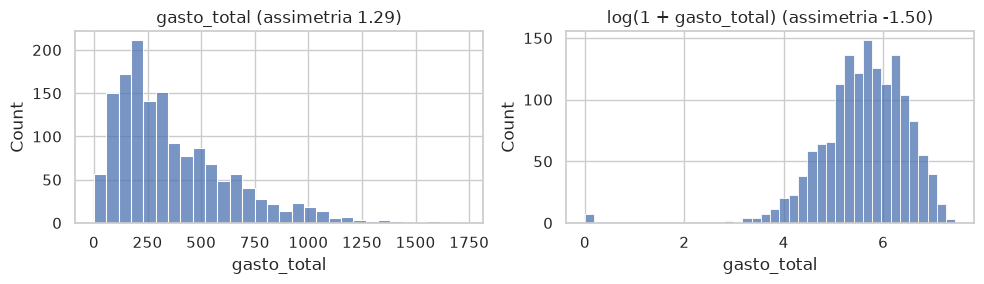

In [17]:
# Executar esta célula

exemplo = dados[["idade", "gasto_total"]].dropna()
comparacao = pd.concat({
    "original": exemplo,
    "min–max": pd.DataFrame(MinMaxScaler().fit_transform(exemplo), columns=exemplo.columns),
    "z-score": pd.DataFrame(StandardScaler().fit_transform(exemplo), columns=exemplo.columns),
}, axis=1)
display(comparacao.describe().loc[["mean", "std", "min", "max"]].round(2))

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(dados["gasto_total"], ax=axs[0]).set(title=f"gasto_total (assimetria {dados['gasto_total'].skew():.2f})")
sns.histplot(np.log1p(dados["gasto_total"]), ax=axs[1]).set(
    title=f"log(1 + gasto_total) (assimetria {np.log1p(dados['gasto_total']).skew():.2f})")
plt.tight_layout()
plt.show()

### 3.5 Codificar variáveis categóricas

Os algoritmos não aceitam texto. Há duas codificações principais, e a escolha depende de as categorias terem ou não **ordem**:

- **one-hot**: uma coluna 0/1 por categoria. Para categorias **sem ordem** (`cidade`, `canal_preferido`). Dar números (Lisboa = 1, Porto = 2…) inventaria uma ordem que não existe;
- **ordinal**: um número por categoria, pela ordem certa. Para categorias **com ordem** (`plano`: Básico < Plus < Premium).


In [18]:
# Executar esta célula

amostra = dados[["cidade", "plano"]].head(4)
one_hot = OneHotEncoder(sparse_output=False).fit(dados[["cidade"]].dropna())
ordinal = OrdinalEncoder(categories=[["Básico", "Plus", "Premium"]])
display(pd.concat([amostra,
                   pd.DataFrame(one_hot.transform(amostra[["cidade"]]), columns=one_hot.get_feature_names_out()),
                   pd.DataFrame(ordinal.fit_transform(amostra[["plano"]]), columns=["plano_ordinal"])], axis=1))

,cidade,plano,cidade_Aveiro,cidade_Braga,cidade_Coimbra,cidade_Faro,cidade_Lisboa,cidade_Porto,plano_ordinal
0,Lisboa,Premium,0.0,0.0,0.0,0.0,1.0,0.0,2.0
1,Braga,Premium,0.0,1.0,0.0,0.0,0.0,0.0,2.0
2,Lisboa,Premium,0.0,0.0,0.0,0.0,1.0,0.0,2.0
3,Faro,Plus,0.0,0.0,0.0,1.0,0.0,0.0,1.0


### 3.6 Separar treino e teste, e montar o pré-processamento

Agora a regra de ouro: **separar os dados de teste antes de aprender qualquer coisa com eles**. Tudo o que é *calculado a partir dos dados* (medianas para imputar, médias e desvios para padronizar, a lista de categorias) é aprendido só com o treino e depois **aplicado** ao teste. O teste representa os clientes futuros, que o modelo nunca viu.

A função `construir_preprocessamento` monta um `ColumnTransformer` que trata cada grupo de colunas:

| Grupo | Passos |
| --- | --- |
| numéricas | imputar a mediana (com indicador de falta) → padronizar |
| categóricas | imputar a mais frequente → one-hot |
| ordinais | imputar a mais frequente → ordinal |


In [19]:
# Executar esta célula

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


def construir_preprocessamento(
    numericas: list[str],
    categoricas: list[str] | None = None,
    ordinais: dict[str, list[str]] | None = None,
) -> ColumnTransformer:
    """ColumnTransformer: imputa e padroniza as numéricas, codifica as categóricas e as ordinais.

    Tudo o que é *aprendido* com os dados (medianas, médias, desvios, categorias) fica aqui
    dentro, para ser ajustado só com os dados de treino e evitar fugas de informação.
    """
    categoricas = categoricas or []
    ordinais = ordinais or {}
    partes = [("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                                ("escalar", StandardScaler())]), numericas)]
    if categoricas:
        partes.append(("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                        ("codificar", OneHotEncoder(handle_unknown="ignore",
                                                                    sparse_output=False))]), categoricas))
    if ordinais:
        partes.append(("ord", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                        ("codificar", OrdinalEncoder(categories=list(ordinais.values())))]),
                       list(ordinais)))
    return ColumnTransformer(partes, verbose_feature_names_out=False)


NUMERICAS = ["idade", "antiguidade_dias", "n_compras", "gasto_total", "gasto_mensal", "ticket_medio",
             "recencia_dias", "n_categorias", "n_devolucoes", "reclamacoes", "pedidos_info", "satisfacao"]
CATEGORICAS = ["cidade", "canal_preferido", "pais"]
ORDINAIS = {"plano": ["Básico", "Plus", "Premium"]}

X = dados[NUMERICAS + CATEGORICAS + list(ORDINAIS)]
y = dados["abandonou"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Treino: {X_treino.shape} | teste: {X_teste.shape} | abandono no treino {y_treino.mean():.1%}, no teste {y_teste.mean():.1%}")

prep = construir_preprocessamento(NUMERICAS, CATEGORICAS, ORDINAIS).set_output(transform="pandas")
X_treino_t = prep.fit_transform(X_treino)       # aprende com o treino…
X_teste_t = prep.transform(X_teste)              # …e só aplica ao teste
print("Atributos depois da transformação:", X_treino_t.shape[1])
X_treino_t.head(3)

Treino: (1125, 16) | teste: (375, 16) | abandono no treino 25.6%, no teste 25.6%
Atributos depois da transformação: 25


,idade,antiguidade_dias,n_compras,gasto_total,gasto_mensal,ticket_medio,recencia_dias,n_categorias,n_devolucoes,reclamacoes,...,cidade_Braga,cidade_Coimbra,cidade_Faro,cidade_Lisboa,cidade_Porto,canal_preferido_app,canal_preferido_loja,canal_preferido_online,pais_Portugal,plano
1127,-1.024,-1.342,-1.291,-0.415,-0.415,3.818,2.614,-0.630,-0.538,-0.662,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
284,-1.584,1.321,-1.076,-0.722,-0.722,0.502,-0.747,-1.546,-0.538,0.133,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0
984,-0.784,1.156,1.283,1.055,1.055,0.399,-0.723,1.200,-0.538,0.133,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


O `stratify=y` garante a mesma taxa de abandono no treino e no teste. Repara que os 16 atributos originais passaram a 25: o one-hot criou uma coluna por cidade e por canal, e a imputação acrescentou indicadores de falta para a idade e a satisfação.


## 4. Redução de dimensionalidade: ficar com o essencial

Mais atributos não é sempre melhor: atributos inúteis acrescentam ruído, tornam o treino mais lento e o modelo mais difícil de explicar. Há duas famílias de técnicas:

- **seleção de atributos** (*feature selection*): ficar com um subconjunto dos atributos originais. Mantém o significado de cada um;
- **extração de atributos**, como o **PCA**: criar poucos atributos novos que combinam os originais. Comprime melhor, mas os novos atributos já não têm um significado simples.

### 4.1 Atributos constantes e redundantes

O primeiro filtro não precisa do alvo: um atributo **constante** não distingue ninguém, e dois atributos **quase perfeitamente correlacionados** dizem a mesma coisa.


In [20]:
# Executar esta célula

def colunas_redundantes(df: pd.DataFrame, limite: float = 0.95) -> list[str]:
    """Colunas numéricas constantes ou com |correlação| > limite com uma coluna anterior."""
    num = df.select_dtypes("number")
    constantes = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
    corr = num.drop(columns=constantes).corr().abs()
    superior = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    correlacionadas = [c for c in superior.columns if (superior[c] > limite).any()]
    return constantes + correlacionadas


print("Valores distintos em pais:", X_treino["pais"].nunique())
redundantes = colunas_redundantes(X_treino_t)
print("Constantes ou redundantes (|r| > 0,95):", redundantes)
print(f"Correlação gasto_total × gasto_mensal: {X_treino['gasto_total'].corr(X_treino['gasto_mensal']):.3f}")

Valores distintos em pais: 1
Constantes ou redundantes (|r| > 0,95): ['pais_Portugal', 'gasto_mensal']
Correlação gasto_total × gasto_mensal: 1.000


`pais` é constante (todos os clientes são de Portugal; depois do one-hot fica `pais_Portugal`, sempre 1) e `gasto_mensal` é só `gasto_total / 9`: tem correlação 1 com ele. Ambos saem. Este é o caso típico de um atributo criado na transformação que afinal não acrescenta nada: o processo é iterativo.


In [21]:
# Executar esta célula

NUMERICAS = [c for c in NUMERICAS if c != "gasto_mensal"]
CATEGORICAS = [c for c in CATEGORICAS if c != "pais"]
X_treino, X_teste = X_treino[NUMERICAS + CATEGORICAS + list(ORDINAIS)], X_teste[NUMERICAS + CATEGORICAS + list(ORDINAIS)]
prep = construir_preprocessamento(NUMERICAS, CATEGORICAS, ORDINAIS).set_output(transform="pandas")
X_treino_t = prep.fit_transform(X_treino)
print("Atributos depois da redução:", X_treino_t.shape[1])

Atributos depois da redução: 23


### 4.2 Relevância para o alvo: informação mútua

A **informação mútua** mede quanto um atributo reduz a incerteza sobre o alvo (0 = nada; quanto maior, mais informativo). Ao contrário da correlação, também apanha relações não lineares. Calcula-se **só com o treino**.


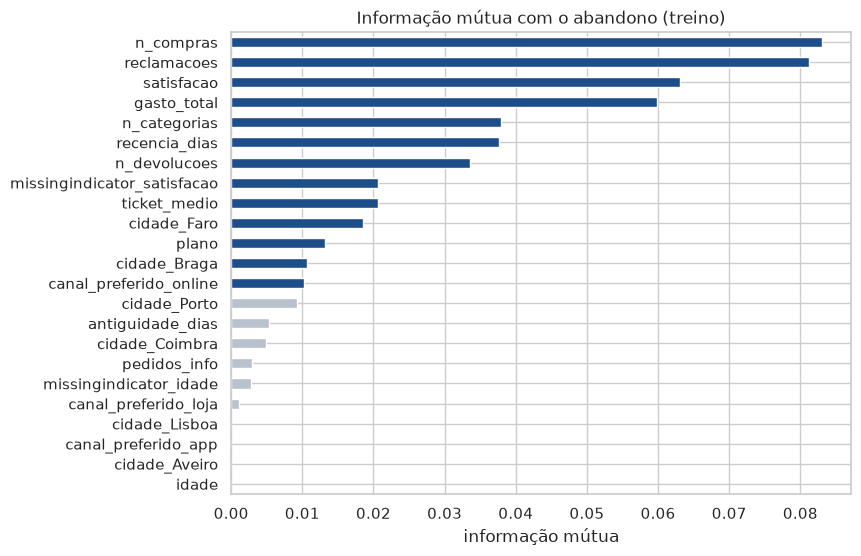

In [22]:
# Executar esta célula

mi = pd.Series(mutual_info_classif(X_treino_t, y_treino, random_state=0), index=X_treino_t.columns)
mi = mi.sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
mi.plot.barh(ax=ax, color=["#1D4E89" if v >= 0.01 else "#B8C2CF" for v in mi])
ax.set(title="Informação mútua com o abandono (treino)", xlabel="informação mútua")
plt.show()

Os atributos de **comportamento** (compras, reclamações, satisfação, gasto, recência) são os mais informativos; a idade e a maioria das cidades quase não dizem nada. Repara também em `missingindicator_satisfacao`: **não ter respondido** ao inquérito é, por si só, informativo, como suspeitámos na secção 2.6. Mas a informação mútua avalia cada atributo **sozinho**: um atributo fraco pode ser útil em combinação com outros. A forma segura de decidir é **experimentar**: comparar, com validação cruzada, o modelo com todos os atributos e com os *k* melhores (`SelectKBest`), com a seleção feita **dentro** do pipeline, em cada partição.


In [23]:
# Executar esta célula

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mi_fixa = partial(mutual_info_classif, random_state=0)

def pipeline_logistico(*passos_extra):
    return Pipeline([("prep", construir_preprocessamento(NUMERICAS, CATEGORICAS, ORDINAIS)), *passos_extra,
                     ("modelo", LogisticRegression(max_iter=1000))])

for nome, pipe in {"todos os atributos": pipeline_logistico(),
                   "8 melhores (SelectKBest)": pipeline_logistico(("selecionar", SelectKBest(mi_fixa, k=8))),
                   "4 melhores (SelectKBest)": pipeline_logistico(("selecionar", SelectKBest(mi_fixa, k=4)))}.items():
    auc = cross_val_score(pipe, X_treino, y_treino, cv=cv, scoring="roc_auc")
    print(f"{nome:<26} AUC = {auc.mean():.3f} ± {auc.std():.3f}")

todos os atributos         AUC = 0.861 ± 0.017


8 melhores (SelectKBest)   AUC = 0.851 ± 0.017


4 melhores (SelectKBest)   AUC = 0.846 ± 0.007


### 4.3 Comprimir com PCA

A **análise de componentes principais** (PCA) cria novos eixos, as *componentes*, que são combinações dos atributos originais, ordenados pela variância que explicam. Se poucas componentes explicarem quase toda a variância, podemos trabalhar só com elas. O PCA exige atributos **padronizados** (secção 3.4) e **não usa o alvo**.


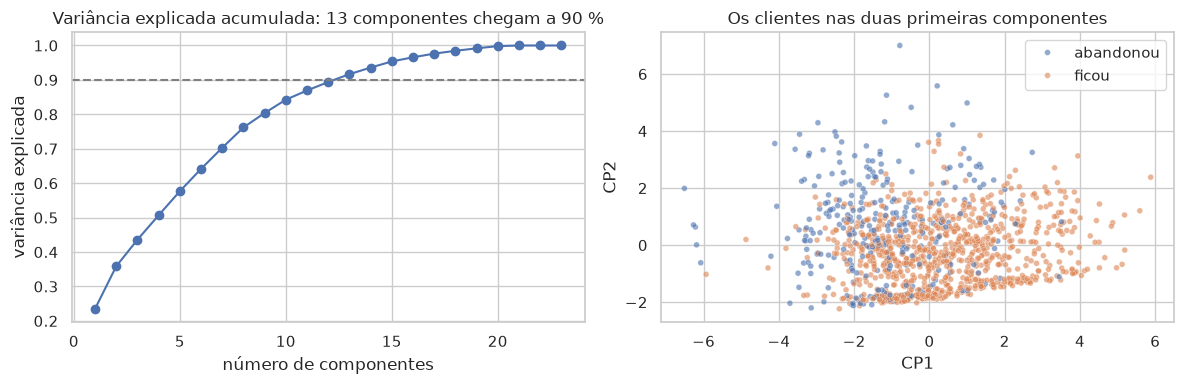

Com PCA (90 % da variância, 13 componentes): AUC = 0.850 ± 0.019


In [24]:
# Executar esta célula

pca = PCA().fit(X_treino_t)
acumulada = np.cumsum(pca.explained_variance_ratio_)
k90 = int(np.argmax(acumulada >= 0.90)) + 1

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(range(1, len(acumulada) + 1), acumulada, marker="o")
axs[0].axhline(0.9, ls="--", color="gray")
axs[0].set(title=f"Variância explicada acumulada: {k90} componentes chegam a 90 %",
           xlabel="número de componentes", ylabel="variância explicada")
duas = pca.transform(X_treino_t)[:, :2]
sns.scatterplot(x=duas[:, 0], y=duas[:, 1], hue=y_treino.map({0: "ficou", 1: "abandonou"}).to_numpy(),
                alpha=0.6, s=18, ax=axs[1])
axs[1].set(title="Os clientes nas duas primeiras componentes", xlabel="CP1", ylabel="CP2")
plt.tight_layout()
plt.show()

auc_pca = cross_val_score(pipeline_logistico(("pca", PCA(n_components=0.90))), X_treino, y_treino, cv=cv, scoring="roc_auc")
print(f"Com PCA (90 % da variância, {k90} componentes): AUC = {auc_pca.mean():.3f} ± {auc_pca.std():.3f}")

Neste problema, com 23 atributos, a redução quase não muda o desempenho: o ganho está na **simplicidade** (menos atributos para recolher e explicar). Com centenas ou milhares de atributos (texto, imagens, sensores, genética), a redução torna-se indispensável. Uma regra prática: usa **seleção** quando precisas de explicar o modelo, e **PCA** quando o que importa é comprimir ou visualizar.

Daqui em diante usamos todos os atributos que sobraram da secção 4.1: são poucos, e assim a interpretação (secção 6) fica mais rica.


## 5. Mineração de dados: encontrar os padrões

Com os dados preparados, a mineração é, curiosamente, a fase com menos código. Aplicamos dois tipos de algoritmos às duas perguntas da direção.

### 5.1 Classificação: quem vai abandonar?

Comparamos vários modelos com **validação cruzada estratificada**, só no treino, cada um num `Pipeline` com o mesmo pré-processamento. O primeiro é um **modelo de referência** (*baseline*) que prevê sempre a classe mais frequente: qualquer modelo útil tem de ser claramente melhor do que ele. Usamos três métricas: a AUC (capacidade de ordenar os clientes por risco), o F1 (equilíbrio entre precisão e sensibilidade na classe «abandonou») e a exatidão.


In [25]:
# Executar esta célula

from sklearn.base import clone
from sklearn.model_selection import cross_validate


def comparar_modelos(
    modelos: dict[str, object],
    preprocessamento: ColumnTransformer,
    X: pd.DataFrame,
    y: pd.Series,
    metricas: tuple[str, ...] = ("roc_auc", "f1", "accuracy"),
    folds: int = 5,
    semente: int = 42,
) -> pd.DataFrame:
    """Validação cruzada estratificada de vários modelos, cada um num Pipeline com o pré-processamento."""
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=semente)
    linhas = {}
    for nome, modelo in modelos.items():
        pipe = Pipeline([("prep", clone(preprocessamento)), ("modelo", modelo)])
        r = cross_validate(pipe, X, y, cv=cv, scoring=list(metricas))
        linhas[nome] = {f"{m}_media": r[f"test_{m}"].mean() for m in metricas} | \
                       {f"{metricas[0]}_dp": r[f"test_{metricas[0]}"].std()}
    return pd.DataFrame(linhas).T.sort_values(f"{metricas[0]}_media", ascending=False).round(3)

modelos = {
    "referência (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "regressão logística": LogisticRegression(max_iter=1000),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    "gradient boosting": HistGradientBoostingClassifier(random_state=42),
}
comparacao = comparar_modelos(modelos, construir_preprocessamento(NUMERICAS, CATEGORICAS, ORDINAIS),
                              X_treino, y_treino)
comparacao

,roc_auc_media,f1_media,accuracy_media,roc_auc_dp
regressão logística,0.861,0.590,0.825,0.017
random forest,0.844,0.546,0.811,0.012
gradient boosting,0.832,0.557,0.801,0.016
referência (classe mais frequente),0.500,0.000,0.744,0.000


Repara na **exatidão da referência**: cerca de 74 %, sem aprender nada, só por dizer sempre «fica». É por isso que a exatidão engana em classes desequilibradas, e que a referência é indispensável. Os três modelos têm AUC próximas; a regressão logística é a melhor e é também a mais fácil de explicar. Quando dois modelos empatam, **escolhe-se o mais simples**.

### 5.2 Agrupamento: que tipos de clientes temos?

Para a segunda pergunta não há alvo: queremos descobrir grupos de clientes parecidos (**aprendizagem não supervisionada**). Usamos o **k-médias** sobre os três atributos RFM, com logaritmo (para reduzir a assimetria) e padronização (porque o k-médias usa distâncias). O **coeficiente de silhueta** (de −1 a 1; maior é melhor) ajuda a escolher o número de grupos.


In [26]:
# Executar esta célula

rfm = dados[["recencia_dias", "n_compras", "gasto_total"]]
rfm_t = StandardScaler().fit_transform(np.log1p(rfm))

silhuetas = {k: silhouette_score(rfm_t, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(rfm_t))
             for k in range(2, 8)}
print({k: round(v, 3) for k, v in silhuetas.items()})

{2: 0.4, 3: 0.328, 4: 0.332, 5: 0.343, 6: 0.351, 7: 0.316}


A silhueta mais alta é com 2 grupos, mas 2 grupos («bons» e «maus» clientes) não orientam campanhas diferentes. A partir de 3, os valores são parecidos. Escolhemos **4 grupos**, um compromisso entre a qualidade estatística e a **utilidade para o negócio**: é uma decisão de interpretação, não só de cálculo. Depois, descrevemos cada grupo pelas médias e, mais importante, pela taxa de abandono, que **não foi usada** para os formar.


In [27]:
# Executar esta célula

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(rfm_t)
dados["segmento"] = kmeans.labels_
perfil = dados.groupby("segmento").agg(clientes=("id_cliente", "size"), recencia_dias=("recencia_dias", "median"),
                                       n_compras=("n_compras", "median"), gasto_total=("gasto_total", "median"),
                                       premium=("plano", lambda s: (s == "Premium").mean()),
                                       abandono=("abandonou", "mean"))
perfil = perfil.sort_values("gasto_total", ascending=False)
nomes = dict(zip(perfil.index, ["Fiéis de valor alto", "Regulares", "Ocasionais", "Em afastamento"]))
perfil.index = perfil.index.map(nomes)
dados["segmento"] = dados["segmento"].map(nomes)
perfil.round(2)

,clientes,recencia_dias,n_compras,gasto_total,premium,abandono
segmento,,,,,,
Fiéis de valor alto,413,18.0,14.0,603.69,0.43,0.10
Regulares,299,3.0,10.0,359.68,0.21,0.16
Ocasionais,565,38.0,7.0,219.61,0.02,0.30
Em afastamento,223,73.0,3.0,85.33,0.00,0.58


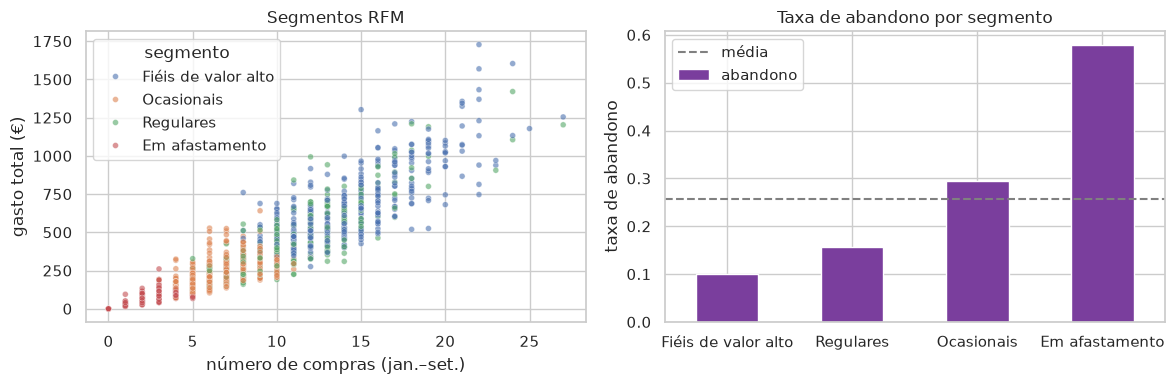

In [28]:
# Executar esta célula

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=dados, x="n_compras", y="gasto_total", hue="segmento", alpha=0.6, s=18, ax=axs[0])
axs[0].set(title="Segmentos RFM", xlabel="número de compras (jan.–set.)", ylabel="gasto total (€)")
perfil["abandono"].plot.bar(ax=axs[1], color="#7A3E9D", rot=0)
axs[1].axhline(dados["abandonou"].mean(), ls="--", color="gray", label="média")
axs[1].set(title="Taxa de abandono por segmento", ylabel="taxa de abandono", xlabel="")
axs[1].legend()
plt.tight_layout()
plt.show()

Os nomes dos segmentos foram dados **por nós**, a olhar para os perfis: o algoritmo só devolve os números 0 a 3. O resultado interessante é que os segmentos, formados **só com o comportamento de compra**, têm taxas de abandono muito diferentes. É um primeiro sinal de conhecimento útil, e um padrão que vamos confirmar na avaliação.

**Experimenta:** a mineração também inclui a **regressão**. Usa uma `RandomForestRegressor` para prever o `gasto_total` a partir de `idade`, `antiguidade_dias`, `plano`, `canal_preferido` e `cidade`, e mede o erro absoluto médio com validação cruzada (`scoring="neg_mean_absolute_error"`). Compara-o com o erro de prever sempre a média (`DummyRegressor`).


In [29]:
# Executar esta célula

# Utiliza esta célula para as tuas experiências

## 6. Interpretação e avaliação: o conhecimento é válido, útil e acionável?

Recorda os quatro adjetivos da definição de KDD: **válido, novo, útil e compreensível**. A avaliação responde a cada um.

### 6.1 Validade: avaliar uma única vez no teste

O modelo escolhido (regressão logística) é treinado com **todo o treino** e avaliado **uma única vez** no teste, que até agora ficou fechado. Se o desempenho no teste for parecido com o da validação cruzada, o modelo generaliza.


AUC no teste: 0.851 (validação cruzada: 0.861)

              precision    recall  f1-score   support

       ficou       0.83      0.93      0.88       279
   abandonou       0.68      0.44      0.53        96

    accuracy                           0.80       375
   macro avg       0.75      0.68      0.70       375
weighted avg       0.79      0.80      0.79       375



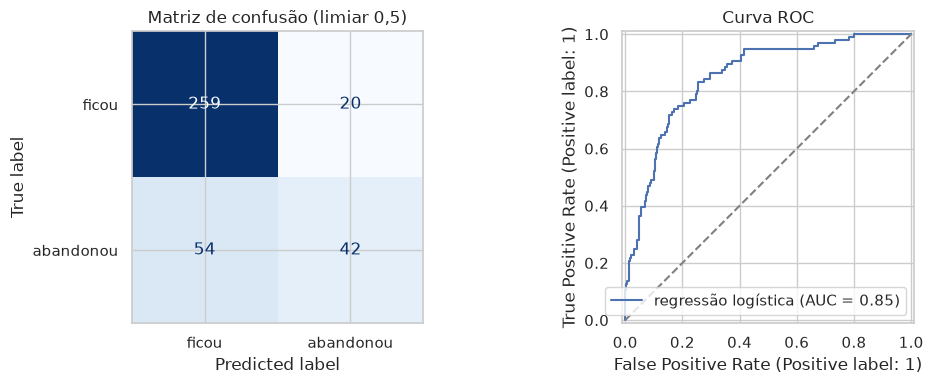

In [30]:
# Executar esta célula

modelo_final = Pipeline([("prep", construir_preprocessamento(NUMERICAS, CATEGORICAS, ORDINAIS)),
                         ("modelo", LogisticRegression(max_iter=1000))]).fit(X_treino, y_treino)
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]

print(f"AUC no teste: {roc_auc_score(y_teste, prob_teste):.3f} "
      f"(validação cruzada: {comparacao.loc['regressão logística', 'roc_auc_media']:.3f})\n")
print(classification_report(y_teste, modelo_final.predict(X_teste), target_names=["ficou", "abandonou"]))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_teste, modelo_final.predict(X_teste), display_labels=["ficou", "abandonou"],
                                        cmap="Blues", ax=axs[0], colorbar=False)
axs[0].set(title="Matriz de confusão (limiar 0,5)")
RocCurveDisplay.from_predictions(y_teste, prob_teste, ax=axs[1], name="regressão logística")
axs[1].plot([0, 1], [0, 1], ls="--", color="gray")
axs[1].set(title="Curva ROC")
plt.tight_layout()
plt.show()

A AUC no teste é próxima da validação cruzada: o modelo é **válido**. Mas, com o limiar habitual de 0,5, o modelo só identifica menos de metade dos clientes que abandonam (sensibilidade, *recall*). Isto não é necessariamente um problema: o limiar de 0,5 é arbitrário. A pergunta da direção não é «quem tem mais de 50 % de probabilidade?», mas sim «**quem contactar, se só podemos contactar 20 %?**».

### 6.2 Utilidade: o *lift*

O ***lift*** responde diretamente ao critério de sucesso (secção 0.2). Ordenamos os clientes do teste pela probabilidade prevista, dividimo-los em 10 grupos (decis) e comparamos a taxa real de abandono de cada grupo com a média.


Contactando os 20 % de maior risco, apanhamos 49% dos clientes que vão abandonar (ao acaso, seriam 20 %).


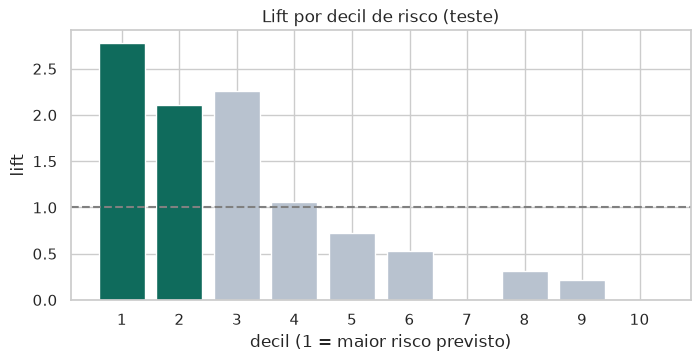

,casos,taxa_real,prob_media,lift
decil,,,,
1,38,0.711,0.829,2.775
2,37,0.541,0.534,2.111
3,38,0.579,0.384,2.262
4,37,0.270,0.279,1.056
5,38,0.184,0.188,0.720
6,37,0.135,0.123,0.528
7,37,0.000,0.079,0.000
8,38,0.079,0.048,0.308
9,37,0.054,0.024,0.211


In [31]:
# Executar esta célula

def lift_por_decil(y_real: pd.Series, probabilidade: np.ndarray) -> pd.DataFrame:
    """Ordena por probabilidade, divide em 10 grupos e compara a taxa real de cada um com a média.

    Um lift de 3 no 1.º decil quer dizer que, entre os 10 % com maior risco previsto,
    a taxa real é três vezes a taxa média: é aí que uma ação (por exemplo, de retenção) rende mais.
    """
    tabela = pd.DataFrame({"real": np.asarray(y_real), "prob": probabilidade})
    tabela["decil"] = pd.qcut(tabela["prob"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    taxa_media = tabela["real"].mean()
    resumo = tabela.groupby("decil", observed=True).agg(casos=("real", "size"),
                                                        taxa_real=("real", "mean"),
                                                        prob_media=("prob", "mean"))
    resumo["lift"] = resumo["taxa_real"] / taxa_media
    return resumo.round(3)


lift = lift_por_decil(y_teste, prob_teste)
captura_20 = (lift["taxa_real"] * lift["casos"]).iloc[:2].sum() / y_teste.sum()
print(f"Contactando os 20 % de maior risco, apanhamos {captura_20:.0%} dos clientes que vão abandonar "
      f"(ao acaso, seriam 20 %).")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(lift.index.astype(str), lift["lift"], color=["#0F6B5C"] * 2 + ["#B8C2CF"] * 8)
ax.axhline(1, ls="--", color="gray")
ax.set(title="Lift por decil de risco (teste)", xlabel="decil (1 = maior risco previsto)", ylabel="lift")
plt.show()
lift

Este é o resultado que interessa à direção: nos dois primeiros decis, a taxa de abandono é **mais do dobro** da média. O critério de sucesso definido no início está cumprido: o modelo é **útil**.

### 6.3 Compreensibilidade: de que depende o risco?

Um modelo que ninguém percebe dificilmente é usado. Dois olhares complementares:
- a **importância por permutação** (N2_05 §5): quanto piora a AUC no teste se baralharmos um atributo;
- os **coeficientes** da regressão logística: o sinal diz se o atributo aumenta (+) ou diminui (−) o risco, e, como os atributos estão padronizados, os tamanhos podem comparar-se.


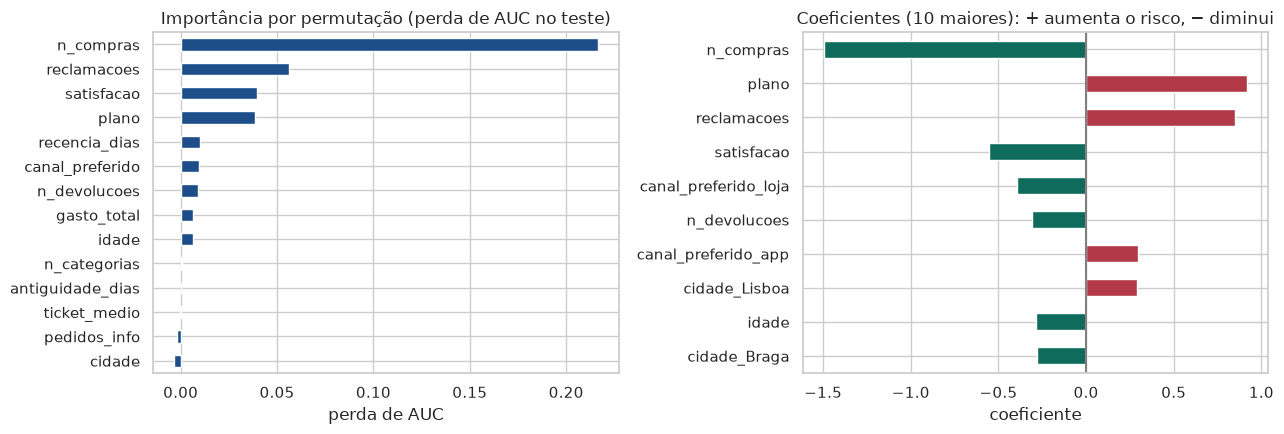

In [32]:
# Executar esta célula

perm = permutation_importance(modelo_final, X_teste, y_teste, scoring="roc_auc", n_repeats=20, random_state=0)
importancia = pd.Series(perm.importances_mean, index=X_teste.columns).sort_values()

nomes_t = modelo_final.named_steps["prep"].get_feature_names_out()
coef = pd.Series(modelo_final.named_steps["modelo"].coef_[0], index=nomes_t)
coef = coef[coef.abs().sort_values().index][-10:]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
importancia.plot.barh(ax=axs[0], color="#1D4E89")
axs[0].set(title="Importância por permutação (perda de AUC no teste)", xlabel="perda de AUC")
coef.plot.barh(ax=axs[1], color=["#B23A48" if v > 0 else "#0F6B5C" for v in coef])
axs[1].axvline(0, color="gray")
axs[1].set(title="Coeficientes (10 maiores): + aumenta o risco, − diminui", xlabel="coeficiente")
plt.tight_layout()
plt.show()

As duas leituras concordam no essencial: o fator mais forte é o **número de compras** (quem compra pouco abandona mais), seguido das **reclamações** (aumentam o risco) e da **satisfação** (diminui o risco). A idade, a cidade e o canal têm efeitos pequenos.

Mas há uma surpresa: o **plano** tem um coeficiente **positivo**, como se um plano superior *aumentasse* o risco. No entanto, os clientes Premium abandonam muito menos do que os Básico. Como é possível? Vejamos as taxas de abandono por plano, primeiro no total e depois em clientes com um número de compras parecido:


In [33]:
# Executar esta célula

faixa = pd.qcut(dados["n_compras"], 3, labels=["poucas compras", "compras médias", "muitas compras"])
print("Taxa de abandono por plano (todos os clientes):", dados.groupby("plano")["abandonou"].mean().round(2).to_dict())
display(pd.crosstab(faixa, dados["plano"], values=dados["abandonou"], aggfunc="mean").round(2)
        .rename_axis(index="taxa de abandono", columns="plano"))
display(pd.crosstab(faixa, dados["plano"]).rename_axis(index="número de clientes", columns="plano"))

Taxa de abandono por plano (todos os clientes): {'Básico': 0.31, 'Plus': 0.21, 'Premium': 0.15}


plano,Básico,Plus,Premium
taxa de abandono,,,
poucas compras,0.45,0.61,0.50
compras médias,0.15,0.21,0.42
muitas compras,0.07,0.07,0.08


plano,Básico,Plus,Premium
número de clientes,,,
poucas compras,458,62,4
compras médias,299,209,53
muitas compras,43,175,197


No total, o plano superior protege (15 % de abandono nos Premium, contra 31 % nos Básico). Mas **dentro de cada faixa de compras** a proteção desaparece. Os clientes Premium abandonam menos porque **compram mais**, e quase todos estão na faixa de «muitas compras». Um Premium que compra pouco é um sinal de afastamento, porque esperávamos que comprasse mais. É por isso que, com o `n_compras` no modelo, o coeficiente do plano fica positivo.

Esta é uma lição importante de interpretação: **um coeficiente lê-se «mantendo os outros atributos constantes»**, e pode ter o sinal contrário da relação que se vê numa tabela simples (é o chamado **paradoxo de Simpson**). Antes de transformar um coeficiente numa conclusão, cruza-o com tabelas como esta.

> **Atenção:** são **associações**, não causas. O modelo diz que os clientes com mais reclamações abandonam mais, não que reduzir as reclamações reduza o abandono (embora seja uma hipótese razoável, a testar, por exemplo, com uma campanha piloto e um grupo de controlo).

### 6.4 É acionável? Do padrão à decisão

O último teste do conhecimento é se leva a **ações concretas**. Juntando a classificação e o agrupamento:


In [34]:
# Executar esta célula

teste = dados.loc[X_teste.index, ["segmento", "abandonou"]].assign(risco=prob_teste)
teste["prioridade"] = teste["risco"] >= np.quantile(prob_teste, 0.80)          # os 20 % de maior risco
acoes = teste.groupby("segmento").agg(clientes=("risco", "size"), risco_medio=("risco", "mean"),
                                      a_contactar=("prioridade", "sum"), abandono_real=("abandonou", "mean"))
acoes.sort_values("risco_medio", ascending=False).round(2)

,clientes,risco_medio,a_contactar,abandono_real
segmento,,,,
Em afastamento,68,0.50,34,0.54
Ocasionais,138,0.28,28,0.28
Regulares,66,0.15,6,0.12
Fiéis de valor alto,103,0.11,7,0.13


Com estes resultados, uma recomendação à direção poderia ser:

| Constatação | Ação proposta | Como medir |
| --- | --- | --- |
| Os 20 % de maior risco concentram mais do dobro da taxa média de abandono | campanha de retenção dirigida a esta lista, em vez de uma campanha geral | comparar com um grupo de controlo sorteado da mesma lista |
| Reclamações e baixa satisfação estão associadas ao abandono | contactar pós-reclamação; acompanhar a resolução | taxa de abandono de quem reclamou, antes e depois |
| O segmento «Em afastamento» tem o maior risco | oferta de reativação (desconto na próxima compra) | compras nos 60 dias seguintes |
| Quem compra pouco abandona muito, em qualquer plano (6.3) | estimular a frequência de compra (vales para a próxima compra), em vez de oferecer só um *upgrade* de plano | número de compras e abandono, por plano |

### Lista de verificação da avaliação

- [x] **Válido:** desempenho estável na validação cruzada e no teste, muito acima da referência.
- [x] **Novo:** a segmentação e o peso das reclamações não eram conhecidos (num caso real, confirmar com a equipa).
- [x] **Útil:** cumpre o critério de sucesso (*lift* nos dois primeiros decis).
- [x] **Compreensível:** os atributos principais têm uma explicação de negócio.
- [ ] **Limitações** a comunicar: dados de um só ano; associações e não causas; o modelo tem de ser **monitorizado** (o comportamento dos clientes muda) e retreinado periodicamente.


## 7. Uma estrutura reutilizável

Ao longo do módulo, cada fase usou funções pequenas: `diagnosticar`, `remover_duplicados`, `construir_preprocessamento`, `comparar_modelos`, `lift_por_decil`… Para as reutilizar noutro projeto, juntamo-las num **módulo**, `kdd.py` (anexo A2, secção 10). E, como o processo é sempre o mesmo, guardamos também a estrutura num **notebook-modelo**.

### 7.1 Lista de verificação por fase

| Fase | Perguntas a fazer | Verificação |
| --- | --- | --- |
| **0. Objetivo** | Qual é a pergunta? Que decisão vai mudar? Qual é o critério de sucesso? | critério escrito antes de ver os dados |
| **1. Seleção** | Que fontes? Que período? Que unidade (uma linha por quê)? O alvo está bem definido? Há informação do futuro? | janelas de observação e de previsão separadas |
| **2. Limpeza** | Duplicados? Categorias inconsistentes? Valores impossíveis? Extremos: erro ou realidade? Porque faltam valores? | `diagnosticar` antes e depois; lista `registo` com cada decisão |
| **3. Transformação** | Que agregações? Que atributos derivados? Que escalas? Que categorias têm ordem? | `merge(..., validate=...)`; transformações aprendidas só no treino |
| **4. Redução** | Há constantes ou redundantes? Que atributos informam o alvo? Compensa comprimir? | comparar com e sem redução em validação cruzada |
| **5. Mineração** | Que tipo de problema (classificação, regressão, agrupamento)? Qual é a referência? | todos os modelos num `Pipeline`; validação cruzada |
| **6. Avaliação** | É válido, novo, útil e compreensível? Que ação proporia? Que limitações tem? | teste usado uma só vez; *lift* ou métrica de negócio; desconfiar de resultados bons demais |

### 7.2 O módulo `kdd.py`

A célula seguinte grava o módulo com todas as funções deste notebook, com docstrings e anotações de tipo (capítulo 25). O ficheiro também está no repositório, ao lado deste notebook.


In [35]:
%%writefile kdd.py
"""kdd.py – funções reutilizáveis para as fases do processo KDD.

Seleção → Limpeza → Transformação → Redução → Mineração → Avaliação

Faz parte do tutorial «Introdução ao Python» (nível IA, módulo 3). Copia este
ficheiro para a pasta do teu projeto e adapta-o: as funções são pequenas de
propósito, para se poderem ler, testar e alterar.
"""
from __future__ import annotations

import unicodedata

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

__all__ = [
    "diagnosticar",
    "normalizar_texto",
    "uniformizar_categorias",
    "remover_duplicados",
    "invalidar_fora_do_intervalo",
    "outliers_iqr",
    "colunas_redundantes",
    "construir_preprocessamento",
    "comparar_modelos",
    "lift_por_decil",
]


# ------------------------------------------------------------------ 2. Limpeza
def diagnosticar(df: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por coluna: tipo, valores em falta, valores distintos e exemplos."""
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "em_falta": df.isna().sum(),
        "pct_falta": (df.isna().mean() * 100).round(1),
        "distintos": df.nunique(dropna=True),
        "exemplos": [df[c].dropna().unique()[:4].tolist() for c in df.columns],
    })
    print(f"{len(df)} linhas × {df.shape[1]} colunas | linhas duplicadas: {df.duplicated().sum()}")
    return resumo


def normalizar_texto(serie: pd.Series, acentos: bool = True) -> pd.Series:
    """Tira espaços nas pontas, põe em minúsculas e (opcionalmente) mantém ou remove acentos."""
    # map(str) em vez de astype("string"): os valores em falta continuam NaN (e não pd.NA),
    # que é o que o scikit-learn espera
    s = serie.map(lambda t: t if pd.isna(t) else str(t)).str.strip().str.lower()
    if not acentos:
        s = s.map(lambda t: t if pd.isna(t) else
                  "".join(ch for ch in unicodedata.normalize("NFKD", t) if not unicodedata.combining(ch)))
    return s


def uniformizar_categorias(serie: pd.Series, mapa: dict[str, str] | None = None) -> pd.Series:
    """Normaliza o texto e aplica um dicionário de correspondências (forma normalizada → valor final)."""
    s = normalizar_texto(serie, acentos=False)
    if mapa:
        s = s.replace(mapa)
    return s


def remover_duplicados(df: pd.DataFrame, chave: str | list[str] | None = None) -> pd.DataFrame:
    """Remove linhas repetidas (por todas as colunas ou pela chave) e diz quantas saíram."""
    antes = len(df)
    limpo = df.drop_duplicates(subset=chave, keep="first").reset_index(drop=True)
    print(f"Duplicados removidos: {antes - len(limpo)} (ficam {len(limpo)} linhas)")
    return limpo


def invalidar_fora_do_intervalo(df: pd.DataFrame, regras: dict[str, tuple[float, float]]) -> pd.DataFrame:
    """Substitui por NaN os valores fora de [mínimo, máximo] de cada coluna. Não altera o original."""
    df = df.copy()
    for coluna, (minimo, maximo) in regras.items():
        fora = ~df[coluna].between(minimo, maximo) & df[coluna].notna()
        print(f"{coluna}: {fora.sum()} valores fora de [{minimo}, {maximo}] → NaN")
        df.loc[fora, coluna] = np.nan
    return df


def outliers_iqr(serie: pd.Series, k: float = 1.5) -> pd.Series:
    """Máscara booleana dos valores fora de [Q1 − k·IQR, Q3 + k·IQR] (regra de Tukey)."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - k * iqr) | (serie > q3 + k * iqr)


# ------------------------------------------------------------------ 4. Redução
def colunas_redundantes(df: pd.DataFrame, limite: float = 0.95) -> list[str]:
    """Colunas numéricas constantes ou com |correlação| > limite com uma coluna anterior."""
    num = df.select_dtypes("number")
    constantes = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
    corr = num.drop(columns=constantes).corr().abs()
    superior = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    correlacionadas = [c for c in superior.columns if (superior[c] > limite).any()]
    return constantes + correlacionadas


# ------------------------------------------------------------------ 3. Transformação
def construir_preprocessamento(
    numericas: list[str],
    categoricas: list[str] | None = None,
    ordinais: dict[str, list[str]] | None = None,
) -> ColumnTransformer:
    """ColumnTransformer: imputa e padroniza as numéricas, codifica as categóricas e as ordinais.

    Tudo o que é *aprendido* com os dados (medianas, médias, desvios, categorias) fica aqui
    dentro, para ser ajustado só com os dados de treino e evitar fugas de informação.
    """
    categoricas = categoricas or []
    ordinais = ordinais or {}
    partes = [("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                                ("escalar", StandardScaler())]), numericas)]
    if categoricas:
        partes.append(("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                        ("codificar", OneHotEncoder(handle_unknown="ignore",
                                                                    sparse_output=False))]), categoricas))
    if ordinais:
        partes.append(("ord", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                        ("codificar", OrdinalEncoder(categories=list(ordinais.values())))]),
                       list(ordinais)))
    return ColumnTransformer(partes, verbose_feature_names_out=False)


# ------------------------------------------------------------------ 5. Mineração
def comparar_modelos(
    modelos: dict[str, object],
    preprocessamento: ColumnTransformer,
    X: pd.DataFrame,
    y: pd.Series,
    metricas: tuple[str, ...] = ("roc_auc", "f1", "accuracy"),
    folds: int = 5,
    semente: int = 42,
) -> pd.DataFrame:
    """Validação cruzada estratificada de vários modelos, cada um num Pipeline com o pré-processamento."""
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=semente)
    linhas = {}
    for nome, modelo in modelos.items():
        pipe = Pipeline([("prep", clone(preprocessamento)), ("modelo", modelo)])
        r = cross_validate(pipe, X, y, cv=cv, scoring=list(metricas))
        linhas[nome] = {f"{m}_media": r[f"test_{m}"].mean() for m in metricas} | \
                       {f"{metricas[0]}_dp": r[f"test_{metricas[0]}"].std()}
    return pd.DataFrame(linhas).T.sort_values(f"{metricas[0]}_media", ascending=False).round(3)


# ------------------------------------------------------------------ 6. Avaliação
def lift_por_decil(y_real: pd.Series, probabilidade: np.ndarray) -> pd.DataFrame:
    """Ordena por probabilidade, divide em 10 grupos e compara a taxa real de cada um com a média.

    Um lift de 3 no 1.º decil quer dizer que, entre os 10 % com maior risco previsto,
    a taxa real é três vezes a taxa média: é aí que uma ação (por exemplo, de retenção) rende mais.
    """
    tabela = pd.DataFrame({"real": np.asarray(y_real), "prob": probabilidade})
    tabela["decil"] = pd.qcut(tabela["prob"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    taxa_media = tabela["real"].mean()
    resumo = tabela.groupby("decil", observed=True).agg(casos=("real", "size"),
                                                        taxa_real=("real", "mean"),
                                                        prob_media=("prob", "mean"))
    resumo["lift"] = resumo["taxa_real"] / taxa_media
    return resumo.round(3)

Writing kdd.py


### 7.3 O processo completo em poucas linhas, e o perigo dos resultados bons demais

Com o módulo, o processo inteiro cabe numa função. A função `preparar_tabela` repete as fases 1 a 3 para uma janela de observação qualquer; a seguir, comparamos os modelos com a janela correta e com uma janela que **inclui o 4.º trimestre**, o erro descrito na secção 1.3.


In [36]:
# Executar esta célula

import importlib

import kdd

importlib.reload(kdd)          # garante a versão acabada de gravar


def preparar_tabela(inicio: str, fim: str) -> pd.DataFrame:
    """Fases 1 a 3: seleciona as vendas da janela, limpa as fontes e devolve uma linha por cliente."""
    corte = pd.Timestamp(fim)
    with sqlite3.connect(PASTA / "loja.db") as con:
        v = pd.read_sql_query(consulta, con, params={"inicio": inicio, "fim": fim})
    con.close()
    v = v[(v["valor"] != 0) & (v["valor"].abs() <= 5000)].assign(data=lambda d: pd.to_datetime(d["data"]))

    c = kdd.remover_duplicados(pd.read_csv(PASTA / "clientes.csv"), chave="id_cliente")
    c["cidade"] = kdd.normalizar_texto(c["cidade"]).str.title()
    c["plano"] = kdd.uniformizar_categorias(c["plano"], {"basico": "Básico", "plus": "Plus", "premium": "Premium"})
    c["estado"] = kdd.uniformizar_categorias(c["estado"])
    c = kdd.invalidar_fora_do_intervalo(c, {"idade": (16, 100)})

    pos = v[v["valor"] > 0]
    agg = pos.groupby("id_cliente").agg(n_compras=("valor", "size"), gasto_total=("valor", "sum"),
                                        ultima=("data", "max"), n_categorias=("categoria", "nunique"))
    agg["recencia_dias"] = (corte - agg.pop("ultima")).dt.days
    agg["n_devolucoes"] = v[v["valor"] < 0].groupby("id_cliente").size()

    t = c.merge(agg, on="id_cliente", how="left", validate="one_to_one").merge(
        apoio, on="id_cliente", how="left", validate="one_to_one")
    t[estruturais] = t[estruturais].fillna(0)
    t["recencia_dias"] = t["recencia_dias"].fillna((corte - pd.Timestamp(inicio)).days)
    t["ticket_medio"] = (t["gasto_total"] / t["n_compras"]).where(t["n_compras"] > 0, 0)
    t["antiguidade_dias"] = (corte - pd.to_datetime(t["data_registo"])).dt.days
    t["abandonou"] = (t["estado"] == "cancelado").astype(int)
    return t


prep_base = kdd.construir_preprocessamento(NUMERICAS, CATEGORICAS, ORDINAIS)
so_logistica = {"regressão logística": LogisticRegression(max_iter=1000)}
for descricao, fim in [("janela correta (jan.–set.)", "2025-09-30"),
                       ("COM o 4.º trimestre (fuga de informação)", "2025-12-31")]:
    tabela = preparar_tabela("2025-01-01", fim)
    r = kdd.comparar_modelos(so_logistica, prep_base, tabela[NUMERICAS + CATEGORICAS + list(ORDINAIS)],
                             tabela["abandonou"])
    print(f"→ {descricao}: AUC = {r['roc_auc_media'].iloc[0]:.3f}\n")

Duplicados removidos: 30 (ficam 1500 linhas)
idade: 4 valores fora de [16, 100] → NaN


→ janela correta (jan.–set.): AUC = 0.861

Duplicados removidos: 30 (ficam 1500 linhas)
idade: 4 valores fora de [16, 100] → NaN


→ COM o 4.º trimestre (fuga de informação): AUC = 0.943



Com o 4.º trimestre incluído, a AUC salta de cerca de 0,86 para cerca de 0,94, sem mudarmos nada no modelo. É **bom demais para ser verdade**, e é falso: a recência e o número de compras passam a refletir o próprio cancelamento (quem cancelou em novembro não comprou em dezembro). No dia em que a loja usasse o modelo, a 30 de setembro, esses dados ainda não existiriam.

> **Regra prática:** quando um resultado parece bom demais, procura primeiro uma fuga de informação. As causas mais comuns são atributos medidos depois do alvo, transformações ajustadas com todos os dados (incluindo o teste) e identificadores ou datas que codificam o alvo.

### 7.4 O notebook-modelo

O notebook **[RLdS_N3_03_Modelo_KDD.ipynb](RLdS_N3_03_Modelo_KDD.ipynb)**, na mesma pasta, tem as sete secções deste módulo (objetivo e seis fases) com as perguntas da lista de verificação e células de código prontas a adaptar, que usam o `kdd.py`. Para o usares com os teus dados:

1. copia o notebook-modelo e o `kdd.py` para a pasta do teu projeto (no Colab, o notebook descarrega o `kdd.py` do repositório, se não o encontrar);
2. preenche a secção 0 (pergunta, decisão, critério de sucesso) **antes** de abrir os dados;
3. substitui a fonte de exemplo pelas tuas fontes, na secção 1;
4. segue as fases por ordem, registando as decisões, e volta atrás sempre que a avaliação o pedir.

[![Abrir o modelo no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/RLdS_N3_03_Modelo_KDD.ipynb)


## 8. Experimenta

### Exercício 1 – Um atributo novo

Na transformação, cria o atributo `taxa_reclamacao` = reclamações ÷ (número de compras + 1), acrescenta-o a `NUMERICAS` e compara a AUC da regressão logística em validação cruzada, com e sem ele. Melhorou? Porque achas que sim ou que não?


In [37]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
dados["taxa_reclamacao"] = dados["reclamacoes"] / (dados["n_compras"] + 1)
for nome, numericas in [("sem taxa_reclamacao", NUMERICAS), ("com taxa_reclamacao", NUMERICAS + ["taxa_reclamacao"])]:
    pipe = Pipeline([("prep", construir_preprocessamento(numericas, CATEGORICAS, ORDINAIS)),
                     ("modelo", LogisticRegression(max_iter=1000))])
    Xe = dados.loc[X_treino.index, numericas + CATEGORICAS + list(ORDINAIS)]
    auc = cross_val_score(pipe, Xe, y_treino, cv=cv, scoring="roc_auc")
    print(f"{nome:<22} AUC = {auc.mean():.3f} ± {auc.std():.3f}")
# A diferença é pequena: a informação já está em «reclamacoes» e «n_compras»,
# e a regressão logística consegue combiná-los. Um atributo derivado ajuda mais
# quando exprime uma relação que o modelo não consegue construir sozinho.
```

</details>


### Exercício 2 – Escolher o limiar

A campanha passou a poder contactar **30 %** dos clientes. Que limiar de probabilidade corresponde a esses 30 %, no teste? Que percentagem dos clientes que abandonam fica coberta? E qual é a precisão (que fração dos contactados abandonaria de facto)?


In [38]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
limiar = np.quantile(prob_teste, 0.70)               # os 30 % de maior risco
contactados = prob_teste >= limiar
cobertura = y_teste[contactados].sum() / y_teste.sum()
precisao = y_teste[contactados].mean()
print(f"Limiar: {limiar:.2f} | contactados: {contactados.mean():.0%} | "
      f"cobertura dos que abandonam: {cobertura:.0%} | precisão: {precisao:.0%}")
```

</details>


### Exercício 3 – Reutilizar a estrutura

Usa o `kdd.py` para analisar outro problema: o conjunto de dados `load_breast_cancer` do scikit-learn (diagnóstico de tumores, 30 atributos numéricos). Faz o diagnóstico, procura atributos redundantes (|r| > 0,95), compara uma regressão logística e uma *random forest* com e sem esses atributos, e calcula o *lift* do melhor modelo num conjunto de teste.


In [39]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.datasets import load_breast_cancer

cancro = load_breast_cancer(as_frame=True)
Xc, yc = cancro.data, cancro.target                       # 1 = benigno
display(kdd.diagnosticar(Xc).head())
redund = kdd.colunas_redundantes(Xc)
print("Redundantes:", redund)

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)
modelos_c = {"regressão logística": LogisticRegression(max_iter=5000),
             "random forest": RandomForestClassifier(n_estimators=300, random_state=42)}
for nome, cols in [("todos", list(Xc.columns)), ("sem redundantes", [c for c in Xc.columns if c not in redund])]:
    print(nome, len(cols), "atributos")
    display(kdd.comparar_modelos(modelos_c, kdd.construir_preprocessamento(cols), Xc_tr[cols], yc_tr))

final = Pipeline([("prep", kdd.construir_preprocessamento(list(Xc.columns))),
                  ("modelo", LogisticRegression(max_iter=5000))]).fit(Xc_tr, yc_tr)
kdd.lift_por_decil(yc_te, final.predict_proba(Xc_te)[:, 1])
```

</details>


## Verifica o que aprendeste

1. Quais são as seis fases do KDD, e que fases se juntam no «pré-processamento» do modelo de cinco fases?
2. Porque é que as vendas de outubro a dezembro não podem ser usadas como atributos neste problema?
3. A regra IQR marcou centenas de vendas como extremas. Porque é que não as apagámos?
4. Porque é que a imputação da mediana fica dentro do *pipeline* e não é feita antes de separar treino e teste?
5. Quando se usa one-hot e quando se usa codificação ordinal?
6. Qual é a diferença entre seleção de atributos e PCA? Quando preferes cada uma?
7. Porque é que a exatidão de 74 % do modelo de referência mostra que a exatidão é uma má métrica neste problema?
8. O que mede o *lift* do 1.º decil, e porque responde melhor à pergunta da direção do que a matriz de confusão com limiar 0,5?

<details>
<summary><b>Ver respostas</b></summary>

1. Seleção, limpeza, transformação, redução, mineração e avaliação. O pré-processamento junta a limpeza, a transformação e a redução.
2. Porque são posteriores ao início da janela de previsão: refletem o próprio cancelamento (quem cancela deixa de comprar) e não existem no momento em que o modelo seria usado. É uma fuga de informação.
3. Porque a maioria eram compras grandes legítimas (dados assimétricos) e devoluções. A regra estatística encontra candidatos; a decisão usa regras de negócio (aqui, só valores 0 e acima de 5000 € eram erros).
4. Porque a mediana é aprendida com os dados. Calculada com todos os dados, usaria informação do teste, e a avaliação ficaria otimista.
5. One-hot para categorias sem ordem (cidade, canal); ordinal para categorias com ordem natural (plano Básico < Plus < Premium).
6. A seleção fica com alguns atributos originais e mantém o seu significado (boa para explicar); o PCA cria combinações novas que comprimem melhor, mas são difíceis de interpretar (bom para comprimir e visualizar).
7. Porque 74 % dos clientes ficam: um modelo que diz sempre «fica» acerta 74 % sem aprender nada. Em classes desequilibradas usam-se a AUC, o F1, a sensibilidade e a precisão.
8. Mede quantas vezes a taxa de abandono nos 10 % de maior risco é maior do que a média. Responde a «quem contactar com um orçamento limitado», que é a decisão real; o limiar 0,5 é arbitrário.

</details>

## Leitura recomendada

- Fayyad, U., Piatetsky-Shapiro, G. e Smyth, P. (1996). «[From Data Mining to Knowledge Discovery in Databases](https://doi.org/10.1609/aimag.v17i3.1230)». *AI Magazine*, 17(3), 37–54. O artigo que definiu o processo KDD.
- Chapman, P. et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS.
- Han, J., Pei, J. e Tong, H. (2022). *Data Mining: Concepts and Techniques* (4.ª ed.). Cambridge, MA: Morgan Kaufmann. Os capítulos sobre pré-processamento cobrem a limpeza, a transformação e a redução em detalhe.
- Santos, M. F. e Azevedo, C. (2005). *Data Mining: Descoberta de Conhecimento em Bases de Dados*. Lisboa: FCA.
- Kaufman, S., Rosset, S., Perlich, C. e Stitelman, O. (2012). «[Leakage in Data Mining: Formulation, Detection, and Avoidance](https://doi.org/10.1145/2382577.2382579)». *ACM Transactions on Knowledge Discovery from Data*, 6(4), 1–21.
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). Sebastopol: O'Reilly Media. O capítulo 2 é um projeto de ponta a ponta.
- [Guia do utilizador do scikit-learn: pré-processamento](https://scikit-learn.org/stable/modules/preprocessing.html), [*pipelines* e `ColumnTransformer`](https://scikit-learn.org/stable/modules/compose.html), [seleção de atributos](https://scikit-learn.org/stable/modules/feature_selection.html) e [armadilhas comuns, incluindo fugas de informação](https://scikit-learn.org/stable/common_pitfalls.html).
- **Módulos relacionados:** N2_01 e N2_02 (pandas e limpeza), N2_04 (classificação e limiares), N2_05 (PCA e agrupamento), anexo A2 (do notebook ao projeto).
